This notebook compares transitioning closed cells (to open cells) with non-transitioning closed cells.

In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

# create dataset combining judge along trajectories with EC ACM-CAP

The following is the same steps as in '/home/jmayer/ACI_research/Code/mesoscale_structure/step4_create_datasets_combining_EC_with_judge_results/dataset2_combine_judge_goes_along_trajectories_with_acmcap.ipynb'. Since that script only saves transitioning clouds, we need to re-do the steps here to keep also the non-transitioning clouds.

## Load judge-GOES along trajectories

In [2]:
#with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes.nc') as ds:
#    bt_with_goes = ds.load()

with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes_BT14.nc') as ds:
    bt_with_goes = ds.load()

In [3]:
bt_with_goes['goes_cat_at_ec_overpass'] = (bt_with_goes.sel(timestep=0).goes_cats)

In [4]:
bt_with_goes

<xarray.Dataset> Size: 81MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/19)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_lat_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_BT14                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_ice_flag_2          (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0

## clean up the dataset

In [5]:
# clean up the bt_with_goes dataset: convert a goes_cats value that is surrounded by goes_cats values of all the same category to that category, even if the middle value is different 
# 1, 1, 1      1, 1, 1
# 1, 3, 1  --> 1, 1, 1
# 1, 1, 1      1, 1, 1

bt_with_goes_cleaned = None
orbits = np.unique(bt_with_goes['orbit'])
for orbit in orbits:
    bt_orbit = bt_with_goes.where(bt_with_goes['orbit'] == orbit, drop=True)
    da = bt_orbit['goes_cats']

    neighbors = [
        da.shift(time_startpoint=-1, timestep=-1), da.shift(time_startpoint=-1, timestep=0), da.shift(time_startpoint=-1, timestep=1),
        da.shift(time_startpoint=0,  timestep=-1),                                           da.shift(time_startpoint=0,  timestep=1),
        da.shift(time_startpoint=1,  timestep=-1), da.shift(time_startpoint=1,  timestep=0), da.shift(time_startpoint=1,  timestep=1),
    ]

    stacked = xr.concat(neighbors, dim="neighbor")

    all_equal = (stacked == stacked.isel(neighbor=0)).all("neighbor")
    no_nan_neighbors = ~stacked.isnull().any("neighbor")
    center_diff = da != stacked.isel(neighbor=0)

    isolated_mask = all_equal & no_nan_neighbors & center_diff
    N_isolated = isolated_mask.sum().values

    surround_val = stacked.isel(neighbor=3)
    corrected = da.where(~isolated_mask, surround_val)
    bt_orbit['goes_cats_original'] = da
    bt_orbit['goes_cats'] = corrected

    if bt_with_goes_cleaned is None:
        bt_with_goes_cleaned = bt_orbit.copy()
    else:
        bt_with_goes_cleaned = xr.concat([bt_with_goes_cleaned, bt_orbit], dim='time_startpoint')
    print(f'Orbit {orbit}: {N_isolated} isolated points corrected')

    #fig, (ax0,ax1) = plt.subplots(1,2, figsize=(10,4))
    #da.T.plot(ax=ax0)
    #corrected.T.plot(ax=ax1)
    #fig.tight_layout()
    #plt.show()


Orbit 01009E: 1 isolated points corrected
Orbit 01024E: 1 isolated points corrected
Orbit 01040E: 0 isolated points corrected
Orbit 01056E: 0 isolated points corrected
Orbit 01071E: 1 isolated points corrected
Orbit 01087E: 0 isolated points corrected
Orbit 01102E: 0 isolated points corrected
Orbit 01133E: 0 isolated points corrected
Orbit 01164E: 1 isolated points corrected
Orbit 01180E: 0 isolated points corrected
Orbit 01195E: 0 isolated points corrected
Orbit 01211E: 0 isolated points corrected
Orbit 01227E: 0 isolated points corrected
Orbit 01242E: 0 isolated points corrected
Orbit 01258E: 0 isolated points corrected
Orbit 01273E: 1 isolated points corrected
Orbit 01289E: 1 isolated points corrected
Orbit 01304E: 0 isolated points corrected
Orbit 01320E: 0 isolated points corrected
Orbit 01335E: 0 isolated points corrected
Orbit 01351E: 1 isolated points corrected
Orbit 01367E: 0 isolated points corrected
Orbit 01382E: 1 isolated points corrected
Orbit 01398E: 0 isolated points co

In [6]:
# manual clean-up for few orbits, where we saw misclassifications of the CNN (some dissipating or forming clouds were classified as open cells):
# '01631E' # patch of dried out clouds? forming clouds?
# '02005E' # misclassification of the CNN
# '05848E' # dissipating clouds (instead of transitioning to open cells)
# '07575E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '07077E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '02518E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06486E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '02518E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06486E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06719E' # patch of dry clouds? forming clouds? (only at latitudes -17 - -19)

bt_with_goes_cleaned = bt_with_goes_cleaned.where(
                            (bt_with_goes_cleaned.orbit != '01631E') 
                            & (bt_with_goes_cleaned.orbit != '02005E') 
                            & (bt_with_goes_cleaned.orbit != '05848E') 
                            & ~((bt_with_goes_cleaned.orbit == '07575E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '07077E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '02518E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06486E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '02518E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06486E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06719E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -17) & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -19))
                            ,
                            drop=True)

In [7]:
bt_with_goes_cleaned

<xarray.Dataset> Size: 84MB
Dimensions:                  (time_startpoint: 12813, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 308kB '01009E' ... '08369E'
Data variables: (12/20)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_BT14                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_ice_flag_2          (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0
    goes_cats_original       (time_startpoint, timestep) float64 4MB nan ... nan

## retrieve time to/from transitions

In [8]:
def get_transition_properties(bt_dataset, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True):
    """
    Find where trajectories transition from cat0 to cat1 (e.g. open to closed cells)
    going backwards or forwards in time from timestep=0.
    
    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with goes_cats, datetime_traj variables
    transition_from_goes_cats : list
        List of MSI categories to transition from (default: [2])
    transition_to_goes_cats : list
        List of GOES categories to transition to (default: [0, 1])
    backward : bool
        Whether to search backwards in time (default: True)

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables:
        - transition_flag: boolean flag indicating if transition occurred
        - transition_timestep: timestep where transition occurs (first stratiform point)
        - transition_datetime: datetime at transition (mean between last non-stratiform and first stratiform)
        - transition_time_diff: time difference from timestep=0 to transition
        - transition_uncertainty: time uncertainty of transition (half the time difference between last non-stratiform and first stratiform)
    """
    
    # Get dimensions
    n_startpoints = len(bt_dataset.time_startpoint)
    
    # Initialize arrays for results
    transition_flag = np.full(n_startpoints, False)
    transition_timestep = np.full(n_startpoints, np.nan)
    transition_datetime = np.full(n_startpoints, np.datetime64('NaT'), dtype='datetime64[ns]')
    transition_time_diff = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    transition_uncertainty = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    # Get timesteps sorted from 0 to negative values
    timesteps = bt_dataset.timestep.values
    if backward:
        timesteps_sorted = np.sort(timesteps)[::-1]  # Descending order: 0, -1, -2, ...
    else:
        timesteps_sorted = np.sort(timesteps)  # Ascending order: 0, 1, 2, ...
    
    for i in range(n_startpoints):
        traj = bt_dataset.isel(time_startpoint=i)
        
        # Check if timestep=0 has the correct goes category to start from
        goes_cat_at_zero = float(traj.sel(timestep=0).goes_cats.values)
        if goes_cat_at_zero not in transition_from_goes_cats:
            continue  # Skip if not starting from desired GOES category
        
        # Get the datetime at timestep=0 for reference
        reference_datetime = traj.sel(timestep=0).datetime_traj.values
            
        # Look through timesteps from 0 backwards to find transition
        last_cat0_timestep = None
        last_cat0_datetime = None
        first_cat1_timestep = None
        first_cat1_datetime = None
        
        for timestep in timesteps_sorted:
            if backward and timestep > 0:
                continue  # Only look at timestep=0 and negative values
            elif not backward and timestep < 0:
                continue  # Only look at timestep=0 and positive values
                
            try:
                cats_value = float(traj.sel(timestep=timestep).goes_cats.values)
                
                # Skip if NaN
                if pd.isna(cats_value):
                    continue
                
                # If still in the from category, keep looking
                if cats_value in transition_from_goes_cats:
                    # update last cat0
                    last_cat0_timestep = timestep
                    last_cat0_datetime = traj.sel(timestep=timestep).datetime_traj.values
                # If the cat value has changed (i.e. clouds have transitioned)
                elif cats_value not in transition_from_goes_cats:
                    # Check if the clouds at timestep are cat1
                    if cats_value in transition_to_goes_cats:
                        first_cat1_timestep = timestep
                        first_cat1_datetime = traj.sel(timestep=timestep).datetime_traj.values
                        break
                    else:
                        # Transition to an unexpected category, stop searching
                        break  
                    
            except (KeyError, ValueError):
                continue  # Skip if timestep doesn't exist or other errors
        
        # If we found a transition, calculate the mean time and uncertainty
        if (first_cat1_timestep is not None and 
            last_cat0_timestep is not None and 
            first_cat1_datetime is not None and 
            last_cat0_datetime is not None):
            
            # Convert to pandas datetime for easier arithmetic
            first_strat_dt = pd.to_datetime(first_cat1_datetime)
            last_non_strat_dt = pd.to_datetime(last_cat0_datetime)
            ref_dt = pd.to_datetime(reference_datetime)
            
            # Calculate mean time between last non-stratiform and first stratiform
            mean_transition_time = last_non_strat_dt + (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate uncertainty (half the time difference between the two points)
            uncertainty = np.abs(first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate time difference from timestep=0 to mean transition time
            time_diff_to_transition = ref_dt - mean_transition_time


            # if transition is during the night (i.e. last cat on day0 is cat0, and first cat on day1 is cat1), BT14 is used as an indicator of the exact transition time
            transition_during_night = (uncertainty > pd.Timedelta(hours=3))
            if transition_during_night and traj.sel(timestep=0).goes_BT14.values is not np.nan:
                # all BT14 values during the night should be between the last cat0 and first cat1 timesteps, so we can use them to find the transition time more precisely
                timesteps_during_night = slice(last_cat0_timestep, first_cat1_timestep) if not backward else slice(first_cat1_timestep, last_cat0_timestep)
                BT14_during_night = traj.sel(timestep=timesteps_during_night).goes_BT14
                # find the timestep where BT14 changes most drastically, which should indicate the transition time
                BT14_diff = np.abs(BT14_during_night.diff(dim='timestep'))
                if len(BT14_diff) > 0 and not np.all(np.isnan(BT14_diff.values)):
                    idx_max_diff = BT14_diff.argmax()
                    last_cat0_timestep = BT14_diff['timestep'][idx_max_diff-1].values
                    first_cat1_timestep = BT14_diff['timestep'][idx_max_diff].values
                    last_cat0_datetime = traj.sel(timestep=last_cat0_timestep).datetime_traj.values
                    first_cat1_datetime = traj.sel(timestep=first_cat1_timestep).datetime_traj.values
                    # update mean_transition_time and time_diff_to_transition to the time corresponding to the max BT14 change
                    mean_transition_time = pd.to_datetime(last_cat0_datetime) + (pd.to_datetime(first_cat1_datetime) - pd.to_datetime(last_cat0_datetime)) / 2
                    time_diff_to_transition = ref_dt - mean_transition_time
                        
                
            
            # Store results
            transition_flag[i] = True
            transition_timestep[i] = first_cat1_timestep
            transition_datetime[i] = mean_transition_time.to_numpy().astype('datetime64[ns]')
            transition_time_diff[i] = time_diff_to_transition.to_numpy().astype('timedelta64[ns]')
            transition_uncertainty[i] = uncertainty.to_numpy().astype('timedelta64[ns]')
    
    # Add results to dataset
    result = bt_dataset.copy()
    result['transition_flag'] = xr.DataArray(transition_flag, dims='time_startpoint')
    result['transition_timestep'] = xr.DataArray(transition_timestep, dims='time_startpoint')
    result['transition_datetime'] = xr.DataArray(transition_datetime, dims='time_startpoint')
    result['transition_time_diff'] = xr.DataArray(transition_time_diff, dims='time_startpoint')
    result['transition_uncertainty'] = xr.DataArray(transition_uncertainty, dims='time_startpoint')
    result['transition_time_diff'] = result.transition_time_diff.dt.total_seconds() / 3600
    result['transition_uncertainty'] = result.transition_uncertainty.dt.total_seconds() / 3600

    # Add attributes
    result['transition_flag'].attrs = {'description': f'Boolean flag indicating if transition from cats = {transition_from_goes_cats} to cats = {transition_to_goes_cats} occurred'}
    result['transition_timestep'].attrs = {'description': 'Timestep where transition from open to stratiform occurs (timestep of first stratiform point)'}
    result['transition_datetime'].attrs = {'description': 'Mean datetime at transition point (mean between last non-stratiform and first stratiform)'}
    result['transition_time_diff'].attrs = {'description': 'Time difference from timestep=0 to mean transition time (positive means transition is earlier)'}
    result['transition_uncertainty'].attrs = {'description': 'Uncertainty in transition time (half the time between last non-stratiform and first stratiform)'}
    
    return result

In [9]:
# Apply to your open cell trajectories
bt_O = bt_with_goes_cleaned.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass == 2, drop=True)
bt_co_back_from_o = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True)
# Check results
print("Transition statistics C -> O backwards from O:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_back_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_back_from_o.time_startpoint)}")

bt_C = bt_with_goes_cleaned.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass == 1, drop=True)
bt_co_forward_from_c = get_transition_properties(bt_C, transition_from_goes_cats=[1], transition_to_goes_cats=[2], backward=False)
# Check results
print("Transition statistics C -> O forwards from C:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_forward_from_c.time_startpoint)}")

Transition statistics C -> O backwards from O:
Trajectories with transitions: 530
Total trajectories: 1181
Transition statistics C -> O forwards from C:
Trajectories with transitions: 455
Total trajectories: 2616


## add ACMCAP information

In [10]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

# only need SEP data
acmcap = acmcap[acmcap.stratus_region_index == 2]

ds_acmcap = acmcap.to_xarray()
ds_acmcap = ds_acmcap.rename({'time_mid':'time_startpoint'})
ds_acmcap = ds_acmcap.swap_dims({'index':'time_startpoint'})
ds_acmcap = ds_acmcap.assign_coords({
    'time_startpoint': ds_acmcap.time_startpoint.values,
    'orbit': ('time_startpoint', ds_acmcap.orbit.values)})
ds_acmcap = ds_acmcap.drop_vars(['index'])

ds_acmcap['time_startpoint'] = ds_acmcap.time_startpoint.dt.round('0.1s')
ds_acmcap = ds_acmcap.assign_coords({'timestep': ('timestep', [0])})

ds_acmcap

<xarray.Dataset> Size: 11MB
Dimensions:                               (time_startpoint: 12979, timestep: 1)
Coordinates:
    orbit                                 (time_startpoint) object 104kB '010...
  * time_startpoint                       (time_startpoint) datetime64[ns] 104kB ...
  * timestep                              (timestep) int64 8B 0
Data variables: (12/106)
    scene_id                              (time_startpoint) int64 104kB 25868...
    stratus_region_index                  (time_startpoint) int64 104kB 2 ... 2
    along_track_mid                       (time_startpoint) float64 104kB 128...
    lon_mid                               (time_startpoint) float64 104kB -85...
    lat_mid                               (time_startpoint) float64 104kB -3....
    lat_min                               (time_startpoint) float64 104kB -3....
    ...                                    ...
    rwc_cbh_perc75                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc95                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc05                        (time_startpoint) float64 104kB nan...
    rain_gini                             (time_startpoint) float64 104kB 0.0...
    rain_lcf                              (time_startpoint) float64 104kB 0.0...
    rain_n_clusters                       (time_startpoint) int64 104kB 0 ... 3

In [11]:
ds_acmcap['rain_fraction_no_zero'] = ds_acmcap['rain_fraction'].where(ds_acmcap['rain_fraction'] != 0, np.nan)
for var in ['cbh_m', 'cth_m', 'lwp', 'ER', 'Nd', 'rwp', 'rain_median_volume_diameter']:
    ds_acmcap[var+'_cv'] = ds_acmcap[var+'_std'] / ds_acmcap[var]
acmcap_climatology_median = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').median()
acmcap_climatology_std = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').std()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


In [12]:
bt_co_forward_from_c['time_startpoint'] = bt_co_forward_from_c.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_forward_from_c, ds_acmcap, join='left')

# Then merge
bt_co_forward_from_c = bt_aligned.merge(acmcap_aligned)

In [18]:
bt_co_back_from_o['time_startpoint'] = bt_co_back_from_o.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_back_from_o, ds_acmcap, join='left')

# Then merge
bt_co_back_from_o = bt_aligned.merge(acmcap_aligned)

# Analysis

In [ ]:
filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/CO_transitions_EC_GOES.nc'
with xr.open_dataset(filename) as ds:
    bt_co_concat = ds.load()

## compare CO clouds with non-transitioning clouds

In [13]:
bt_c_non_co_trans = bt_co_forward_from_c.where(((bt_co_forward_from_c.transition_flag==False) & 
                                               (bt_co_forward_from_c.goes_cats.sel(timestep=0).drop('timestep') == bt_co_forward_from_c.cats)), drop=True)
tmp = bt_c_non_co_trans.sel(timestep = slice(0,30)).goes_cats.fillna(-1)
enough_datapoints_along_track = (tmp.isin([0,1,2,3,4,5]).sum(dim='timestep')) >= 6
always_closed_cell = tmp.isin([-1,1]).all(dim='timestep')

bt_non_trans_c = bt_c_non_co_trans.where(enough_datapoints_along_track & always_closed_cell, drop=True)
print(f'Number of trajectories that stay closed-cell: {len(bt_non_trans_c.time_startpoint)}')

bt_co_transitioning_c = bt_co_forward_from_c.where(bt_co_forward_from_c.transition_flag == True, drop=True)
print(f'Number of trajectories that transition from closed to open cell: {len(bt_co_transitioning_c.time_startpoint)}')

Number of trajectories that stay closed-cell: 330
Number of trajectories that transition from closed to open cell: 455


/tmp/ipykernel_2493618/411393781.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  (bt_co_forward_from_c.goes_cats.sel(timestep=0).drop('timestep') == bt_co_forward_from_c.cats)), drop=True)


In [14]:
bt_non_trans_c

<xarray.Dataset> Size: 2MB
Dimensions:                               (time_startpoint: 330, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 3kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 3kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 114kB ...
    lon_traj                              (time_startpoint, timestep) float64 114kB ...
    plev_traj                             (time_startpoint, timestep) float64 114kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 114kB ...
    goes_cats                             (time_startpoint, timestep) float64 114kB ...
    goes_cert                             (time_startpoint, timestep) float64 114kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 3kB 0.095...
    lwp_cv                                (time_startpoint) float64 3kB 0.624...
    ER_cv                                 (time_startpoint) float64 3kB 0.337...
    Nd_cv                                 (time_startpoint) float64 3kB 0.165...
    rwp_cv                                (time_startpoint) float64 3kB nan ....
    rain_median_volume_diameter_cv        (time_startpoint) float64 3kB nan ....

<>:63: SyntaxWarning: invalid escape sequence '\m'
<>:69: SyntaxWarning: invalid escape sequence '\D'
<>:70: SyntaxWarning: invalid escape sequence '\D'
<>:63: SyntaxWarning: invalid escape sequence '\m'
<>:69: SyntaxWarning: invalid escape sequence '\D'
<>:70: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2493618/3388405974.py:63: SyntaxWarning: invalid escape sequence '\m'
  ax[2,1].set_xlabel('$r_e$ / $\mu$')
/tmp/ipykernel_2493618/3388405974.py:69: SyntaxWarning: invalid escape sequence '\D'
  plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='$\Delta$t < -10h'),
/tmp/ipykernel_2493618/3388405974.py:70: SyntaxWarning: invalid escape sequence '\D'
  plt.Line2D([0], [0], color=colors[2], lw=4, ls=line_styles[2], label='$\Delta$t >= -10h')


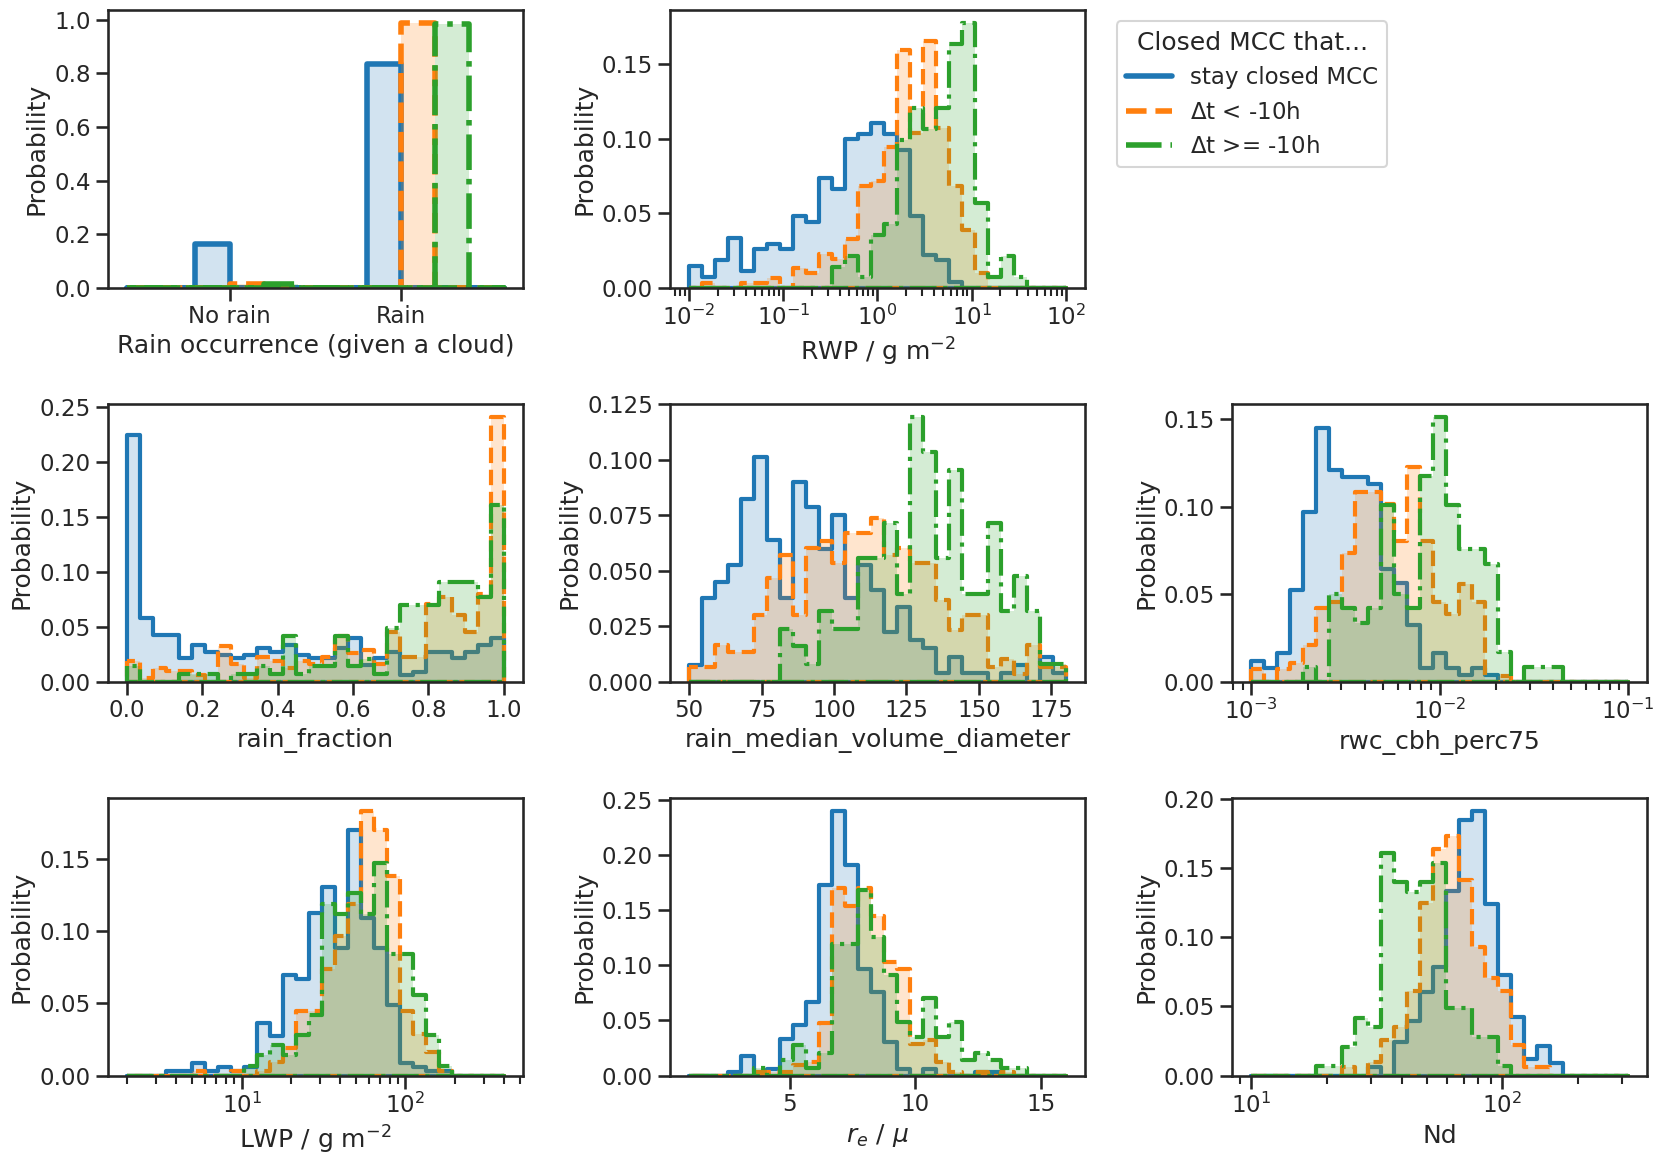

In [15]:
line_styles = ['-', '--', '-.']
colors = sns.color_palette('tab10')
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


fig, ax = plt.subplots(3,3, figsize=(17, 12))
for j,dffil in enumerate([
    bt_non_trans_c, 
    bt_co_transitioning_c.where((bt_co_transitioning_c.transition_time_diff < -10), drop=True),
    bt_co_transitioning_c.where((bt_co_transitioning_c.transition_time_diff >= -10), drop=True)
    ]):
    sns.histplot(ax=ax[0,0], x=(dffil['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', lw=4, color=colors[j], ls=line_styles[j])

    sns.histplot(
        ax=ax[0,1], x=dffil['rwp']*1e3, bins=np.logspace(-2,2,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])

    sns.histplot(
        ax=ax[1,0], x=dffil['rain_fraction'], bins=np.linspace(0,1,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    sns.histplot(
        ax=ax[1,1], x=dffil['rain_median_volume_diameter']*1e6, bins=np.linspace(5e1, 1.8e2, 30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    sns.histplot(
        ax=ax[1,2], x=dffil['rwc_cbh_perc75']*1e3, bins=np.logspace(-3, -1, 30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    
    sns.histplot(
        ax=ax[2,0], x=dffil['lwp']*1e3, bins=np.logspace(0.3,2.6,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])

    sns.histplot(
        ax=ax[2,1], x=dffil['ER']*1e6, bins=np.linspace(1,16,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    sns.histplot(
        ax=ax[2,2], x=dffil['Nd']*1e-6, bins=np.logspace(1,2.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])


ax[0,0].set_xticks([0.1,1.1])
ax[0,0].set_xticklabels(['No rain', 'Rain'])
ax[0,0].set_xlabel('Rain occurrence (given a cloud)')
ax[0,1].set_xscale('log')
ax[0,1].set_xlabel('RWP / g m$^{-2}$')
ax[0,2].axis('off')
ax[1,2].set_xscale('log')
ax[2,0].set_xscale('log')
ax[2,0].set_xlabel('LWP / g m$^{-2}$')
ax[2,1].set_xscale('linear')
ax[2,1].set_xlabel('$r_e$ / $\mu$')
ax[2,2].set_xscale('log')

fig.tight_layout()
legend_handles = [
    plt.Line2D([0], [0], color=colors[0], lw=4, ls=line_styles[0], label='stay closed MCC'),
    plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='$\Delta$t < -10h'),
    plt.Line2D([0], [0], color=colors[2], lw=4, ls=line_styles[2], label='$\Delta$t >= -10h')
]
ax[0,1].legend(title='Closed MCC that...', handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')

In [17]:
tmp

,lat_traj,lon_traj,plev_traj,datetime_traj,goes_cats,goes_cert,goes_ice_flag,goes_cloud_cover,goes_ot_gt_1,goes_ot_gt_5,...,goes_lon_mid_2,goes_cat_at_ec_overpass,goes_cats_original,transition_flag,transition_timestep,transition_datetime,transition_time_diff,transition_uncertainty,timestep,orbit
time_startpoint,,,,,,,,,,,,,,,,,,,,,
2024-08-03 19:38:05.087247424,-11.923322,-85.232727,975.0,2024-08-03 18:00:00,2.0,0.996296,0.0,0.818115,0.757080,0.425537,...,-85.239917,2.0,2.0,1.0,-4.0,2024-08-03 13:00:00,5.0,8.0,0,01040E
2024-08-03 19:38:13.151312000,-12.444490,-85.332359,975.0,2024-08-03 18:00:00,2.0,0.999803,0.0,0.734863,0.639648,0.287598,...,-85.340652,2.0,2.0,1.0,-8.0,2024-08-03 09:00:00,9.0,8.0,0,01040E
2024-08-03 19:38:21.215376000,-12.965620,-85.432388,975.0,2024-08-03 18:00:00,2.0,0.999919,0.0,0.775146,0.659912,0.277588,...,-85.423026,2.0,2.0,1.0,-8.0,2024-08-03 09:00:00,9.0,8.0,0,01040E
2024-08-03 19:38:29.279441024,-13.486680,-85.532722,975.0,2024-08-03 18:00:00,2.0,0.999521,0.0,0.715332,0.608154,0.230957,...,-85.527049,2.0,2.0,1.0,-8.0,2024-08-03 09:00:00,9.0,8.0,0,01040E
2024-08-03 19:38:37.343505088,-14.007681,-85.633316,975.0,2024-08-03 18:00:00,2.0,0.989679,0.0,0.505127,0.418213,0.132812,...,-85.631791,2.0,2.0,1.0,-4.0,2024-08-03 13:00:00,5.0,8.0,0,01040E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-12 19:51:02.329015040,-8.278388,-89.571037,975.0,2025-11-12 18:00:00,2.0,0.995656,0.0,0.938232,0.938232,0.395020,...,-89.566282,2.0,2.0,1.0,-24.0,2025-11-11 19:00:00,23.0,1.0,0,08291E
2025-11-12 19:51:58.777468928,-11.930604,-90.266205,975.0,2025-11-12 18:00:00,2.0,0.728652,0.0,0.933105,0.933105,0.394531,...,-90.259157,2.0,2.0,1.0,-4.0,2025-11-12 13:00:00,5.0,8.0,0,08291E
2025-11-16 19:30:20.330722048,-14.020885,-85.123550,975.0,2025-11-16 18:00:00,2.0,0.648997,0.0,0.992188,0.992188,0.455811,...,-85.115418,2.0,2.0,1.0,-4.0,2025-11-16 13:00:00,5.0,8.0,0,08353E


/tmp/ipykernel_2493618/533491473.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
/tmp/ipykernel_2493618/533491473.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
/tmp/ipykernel_2493618/533491473.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warni

Text(0.5, 1.0, 'Mean RWP given LWP')

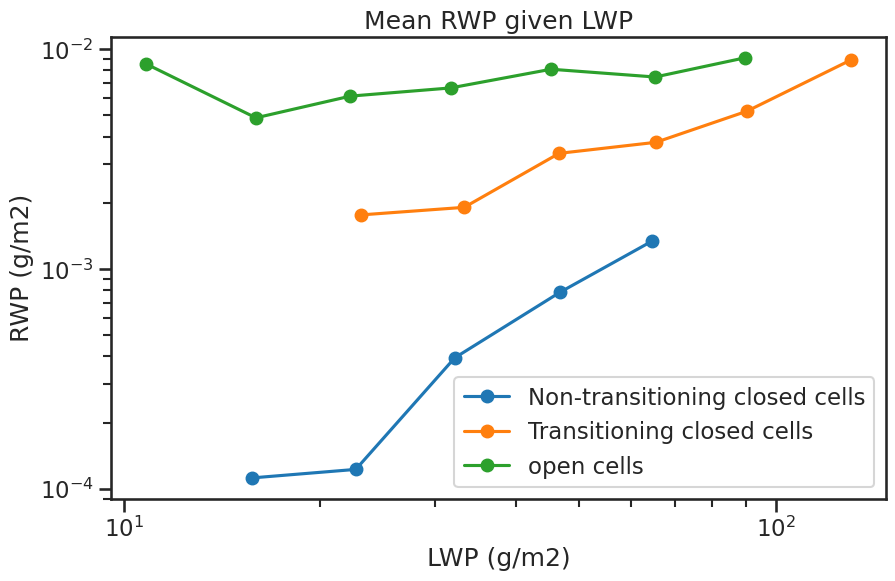

In [19]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in [(bt_non_trans_c, 'Non-transitioning closed cells'), (bt_co_transitioning_c, 'Transitioning closed cells'), (bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells')]:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    #tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP')

<>:5: SyntaxWarning: invalid escape sequence '\D'
<>:5: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2544272/1476148349.py:5: SyntaxWarning: invalid escape sequence '\D'
  data_list.append((tmp, f'{time_diffs[i]} <= $\Delta$t < {time_diffs[i+1]} hours'))


Text(0.5, 1.0, 'Mean RWP given LWP')

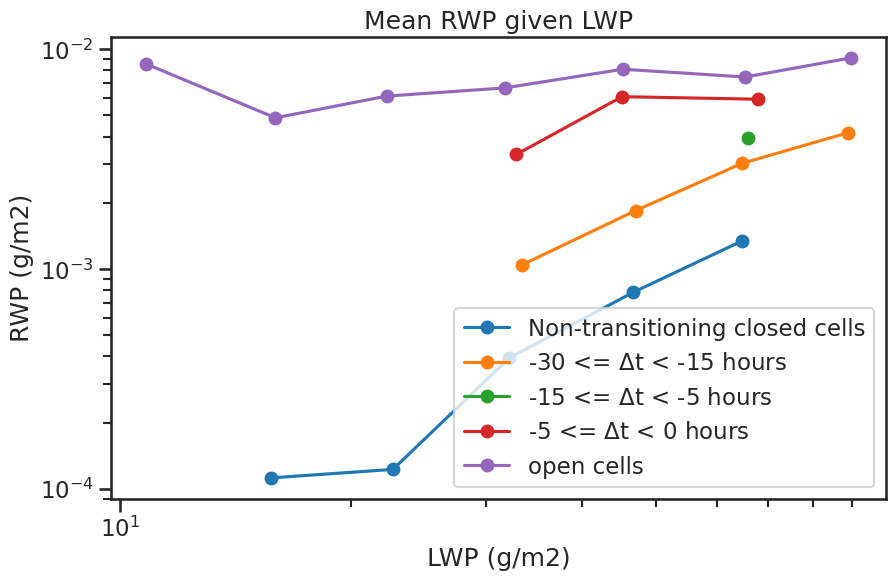

In [ ]:
data_list = [(bt_non_trans_c, 'Non-transitioning closed cells')]
time_diffs = [-30, -15, -5, 0]
for i in range(len(time_diffs)-1):
    tmp = bt_co_transitioning_c.where((bt_co_transitioning_c.transition_time_diff >= time_diffs[i]) & (bt_co_transitioning_c.transition_time_diff < time_diffs[i+1]), drop=True)
    data_list.append((tmp, f'{time_diffs[i]} <= $\Delta$t < {time_diffs[i+1]} hours'))
data_list.append((bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells'))

fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in data_list:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    #tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20)), observed=False).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20)), observed=False).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP')

/tmp/ipykernel_2544272/2783465273.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
/tmp/ipykernel_2544272/2783465273.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
/tmp/ipykernel_2544272/2783465273.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this

Text(0.5, 1.0, 'Mean RWP given LWP')

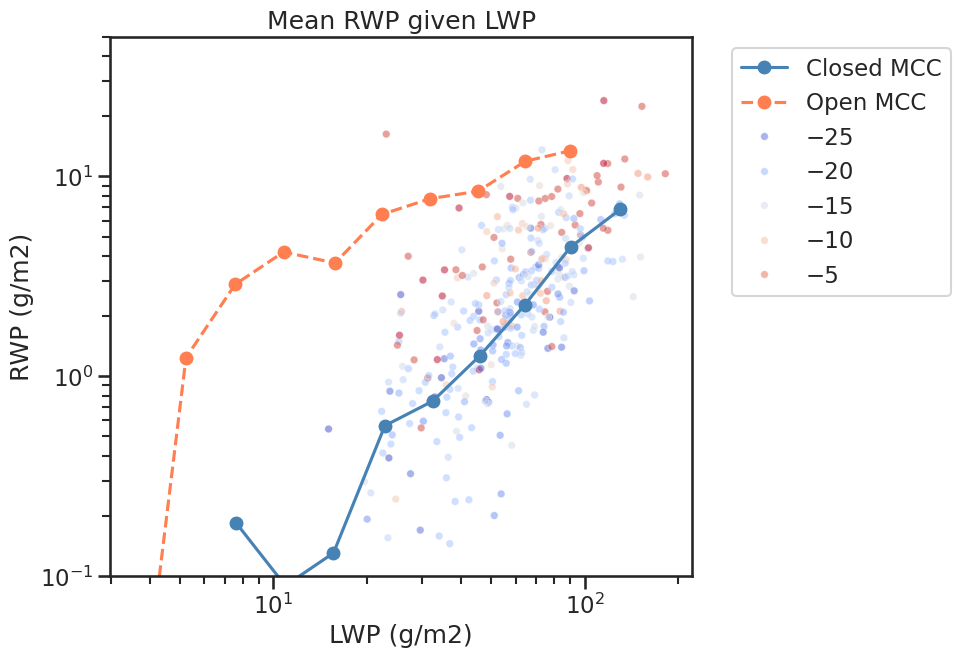

In [ ]:
sns.set_context("talk", font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

cats_names = {
    1: 'Closed MCC',
    2: 'Open MCC'
    }

catcolors = {}
catcolors[1] = 'steelblue'
catcolors[2] = 'coral'
line_styles = [(0, (3, 1, 1, 1)), '-', '--', '-.', (0,(3,1,1,1,1,1)), ':']

fig, ax = plt.subplots(1,1,figsize=(7.5,7))
for i in [1,2]:
    tmp = (ds_acmcap.where(ds_acmcap.cats == i, drop=True)) # dffil[(dffil.cats==i)]
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True, marker='o', ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])

bt_co_c = bt_co_concat.where(bt_co_concat.transition_time_diff <= 0)
#for t in np.unique(bt_co_c.transition_time_diff):
#    tmp = bt_co_c.where(bt_co_c.transition_time_diff == t, drop=True)
#    tmp = tmp[['rwp','lwp']]
#    tmp = tmp.to_dataframe()
#    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
#    tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
#    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
#    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
#    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 2, np.nan)
#    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True, marker='o', ax=ax, label=t)

sns.scatterplot(data=bt_co_c.where(bt_co_c.transition_time_diff <= 0), x=bt_co_c['lwp']*1e3, y=bt_co_c['rwp']*1e3, hue='transition_time_diff', palette='coolwarm', legend=True, s=30, ax=ax, alpha=0.5)

ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_ylim(1e-1,5e1)
ax.set_xlabel('LWP (g/m2)')
ax.set_ylabel('RWP (g/m2)')
ax.set_title('Mean RWP given LWP')

/tmp/ipykernel_1048858/2661582944.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_given_lon = tmp[['lon_mid','lwp']].groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).mean()
/tmp/ipykernel_1048858/2661582944.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_given_lon['size'] = tmp.groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).size()
/tmp/ipykernel_1048858/2661582944.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default

Text(0.5, 1.0, 'Mean lwp given lon_mid')

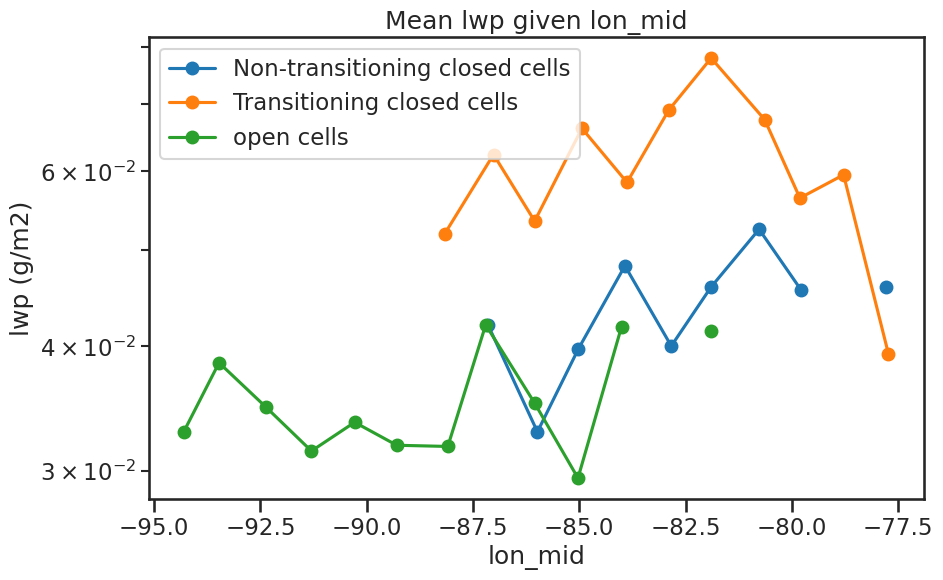

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in [(bt_non_trans_c, 'Non-transitioning closed cells'), (bt_co_transitioning_c, 'Transitioning closed cells'), (bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells')]:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    lwp_given_lon = tmp[['lon_mid','lwp']].groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).mean()
    lwp_given_lon['size'] = tmp.groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).size()
    lwp_given_lon['lwp'] = lwp_given_lon['lwp'].where(lwp_given_lon['size'] >= 20, np.nan)
    lwp_given_lon.plot(y='lwp', x='lon_mid', logy=True, logx=False,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('lon_mid')
plt.ylabel('lwp (g/m2)')
plt.title('Mean lwp given lon_mid')

/tmp/ipykernel_2493618/80815408.py:8: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

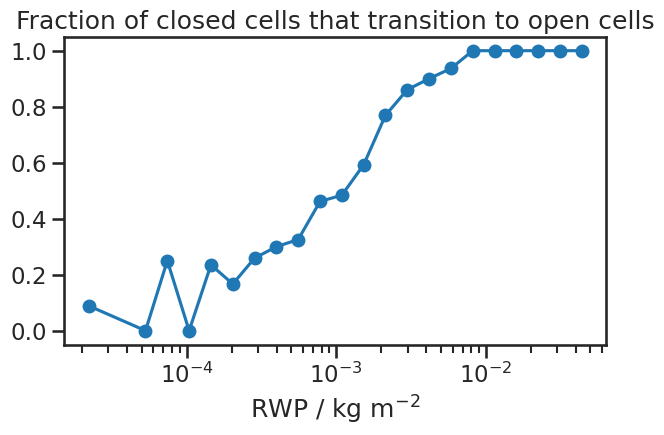

In [20]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-4.5, -1, 25)
bins[0] = 0
rwp_bin_centers = (bins[:-1] + bins[1:]) / 2
rwp_hist_trans = np.histogram(bt_co_transitioning_c.rwp, bins=bins)[0]
rwp_hist_non_trans = np.histogram(bt_non_trans_c.rwp, bins=bins)[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwp_bin_centers, rwp_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWP / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/774150847.py:8: RuntimeWarning: invalid value encountered in divide
  rain_rate_cbh_transition_prob = rain_rate_cbh_hist_trans / rain_rate_cbh_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

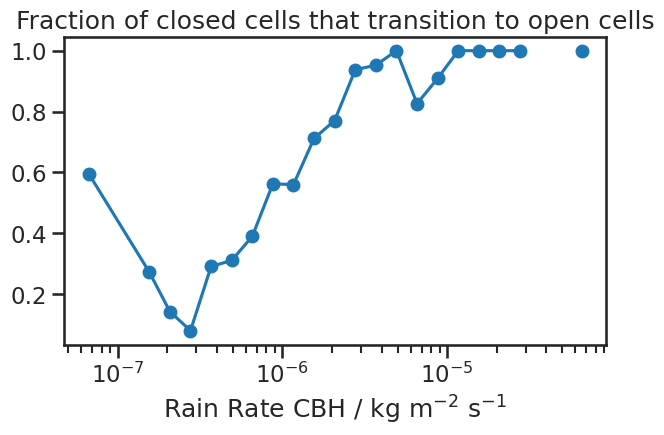

In [ ]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-7., -4., 25)
bins[0] = 0
rain_rate_cbh_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_rate_cbh_hist_trans = np.histogram(bt_co_transitioning_c.rain_rate_cbh, bins=bins)[0]
rain_rate_cbh_hist_non_trans = np.histogram(bt_non_trans_c.rain_rate_cbh, bins=bins)[0]
rain_rate_cbh_hist_total = rain_rate_cbh_hist_trans + rain_rate_cbh_hist_non_trans
rain_rate_cbh_transition_prob = rain_rate_cbh_hist_trans / rain_rate_cbh_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rain_rate_cbh_bin_centers, rain_rate_cbh_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('Rain Rate CBH / kg m$^{-2}$ s$^{-1}$')
plt.title('Fraction of closed cells that transition to open cells')
plt.show()

/tmp/ipykernel_1499759/2139391749.py:8: RuntimeWarning: invalid value encountered in divide
  rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

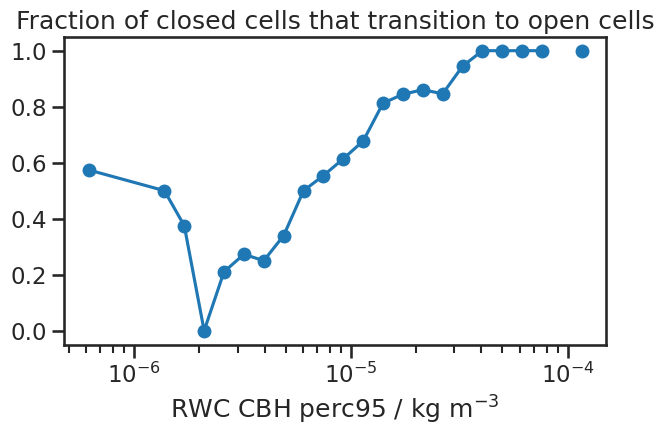

In [ ]:
bins = np.logspace(-6., -3.8, 25)
bins[0] = 0
rwc_cbh_perc95_bin_centers = (bins[:-1] + bins[1:]) / 2
    
rwc_cbh_perc95_hist_trans = np.histogram(bt_co_transitioning_c.rwc_cbh_perc95, bins=bins)[0]
rwc_cbh_perc95_hist_non_trans = np.histogram(bt_non_trans_c.rwc_cbh_perc95, bins=bins)[0]
rwc_cbh_perc95_hist_total = rwc_cbh_perc95_hist_trans + rwc_cbh_perc95_hist_non_trans
rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwc_cbh_perc95_bin_centers, rwc_cbh_perc95_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWC CBH perc95 / kg m$^{-3}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/974125676.py:8: RuntimeWarning: invalid value encountered in divide
  rain_rate_subcloud_transition_prob = rain_rate_subcloud_hist_trans / rain_rate_subcloud_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

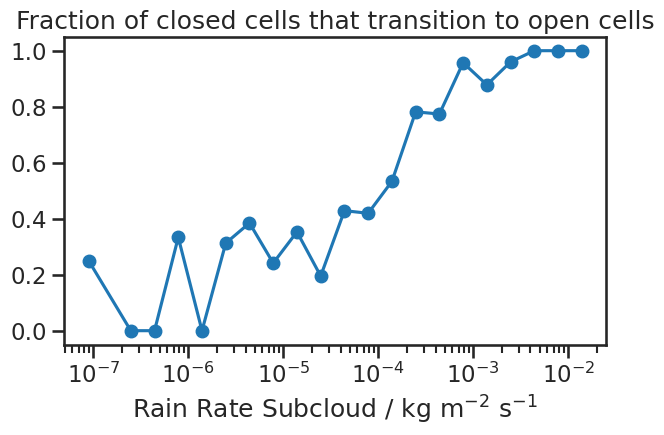

In [ ]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-7., -1., 25)
bins[0] = 0
rain_rate_subcloud_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_rate_subcloud_hist_trans = np.histogram(bt_co_transitioning_c.rain_rate_subcloud, bins=bins)[0]
rain_rate_subcloud_hist_non_trans = np.histogram(bt_non_trans_c.rain_rate_subcloud, bins=bins)[0]
rain_rate_subcloud_hist_total = rain_rate_subcloud_hist_trans + rain_rate_subcloud_hist_non_trans
rain_rate_subcloud_transition_prob = rain_rate_subcloud_hist_trans / rain_rate_subcloud_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rain_rate_subcloud_bin_centers, rain_rate_subcloud_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('Rain Rate Subcloud / kg m$^{-2}$ s$^{-1}$')
plt.title('Fraction of closed cells that transition to open cells')

Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

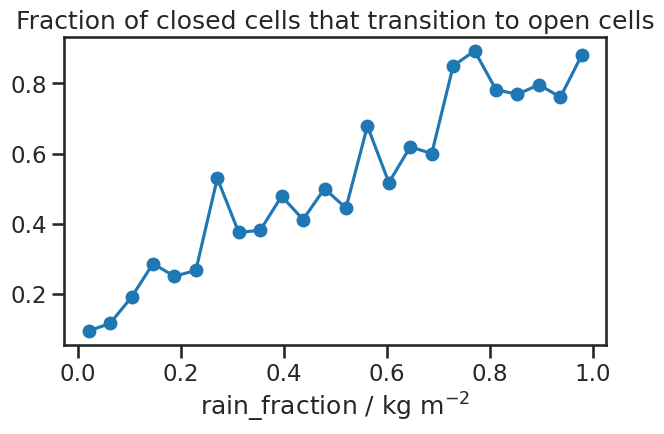

In [ ]:
# plot probability that cloud will transition vs rain_fraction
bins = np.linspace(0, 1, 25)
bins[0] = 0
rain_fraction_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_fraction_hist_trans = np.histogram(bt_co_transitioning_c.rain_fraction, bins=bins)[0]
rain_fraction_hist_non_trans = np.histogram(bt_non_trans_c.rain_fraction, bins=bins)[0]
rain_fraction_hist_total = rain_fraction_hist_trans + rain_fraction_hist_non_trans
rain_fraction_transition_prob = rain_fraction_hist_trans / rain_fraction_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rain_fraction_bin_centers, rain_fraction_transition_prob, marker='o')
plt.xlabel('rain_fraction / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/437304266.py:8: RuntimeWarning: invalid value encountered in divide
  rain_median_volume_diameter_transition_prob = rain_median_volume_diameter_hist_trans / rain_median_volume_diameter_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

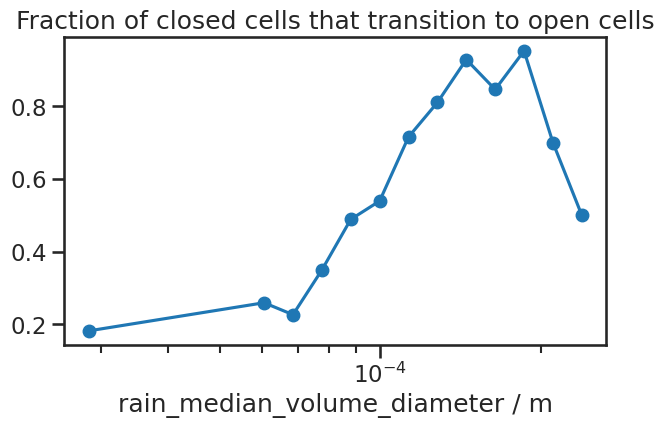

In [ ]:
# plot probability that cloud will transition vs rain_median_volume_diameter
bins = np.logspace(-4.3, -3, 25)
bins[0] = 0
rain_median_volume_diameter_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_median_volume_diameter_hist_trans = np.histogram(bt_co_transitioning_c.rain_median_volume_diameter, bins=bins)[0]
rain_median_volume_diameter_hist_non_trans = np.histogram(bt_non_trans_c.rain_median_volume_diameter, bins=bins)[0]
rain_median_volume_diameter_hist_total = rain_median_volume_diameter_hist_trans + rain_median_volume_diameter_hist_non_trans
rain_median_volume_diameter_transition_prob = rain_median_volume_diameter_hist_trans / rain_median_volume_diameter_hist_total
plt.figure(figsize=(7, 4))
plt.xscale('log')
plt.plot(rain_median_volume_diameter_bin_centers, rain_median_volume_diameter_transition_prob, marker='o')
plt.xlabel('rain_median_volume_diameter / m')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/3271198326.py:12: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

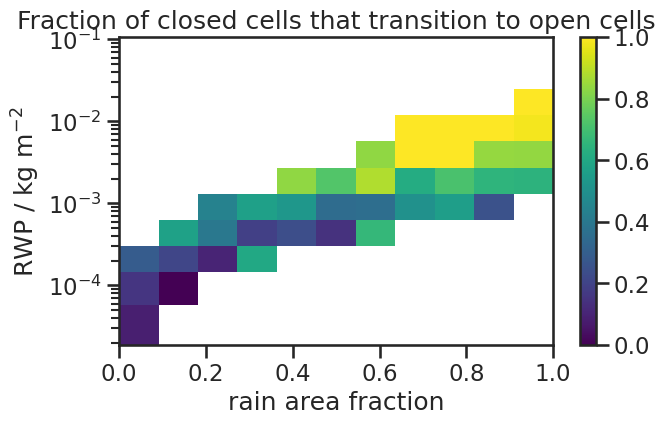

In [ ]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.linspace(0, 1, 12)

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_fraction_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob) 
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_fraction_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_fraction_bin': rain_fraction_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('rain area fraction')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/1521876788.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

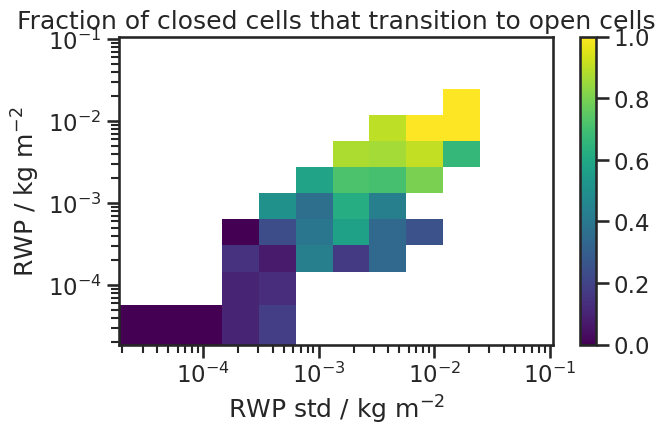

In [ ]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -1, 12)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rwp_std_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rwp_std, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rwp_std, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob) 
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rwp_std_bin'], coords={'rwp_bin': rwp_bin_centers, 'rwp_std_bin': rwp_std_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('RWP std / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/1700057083.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

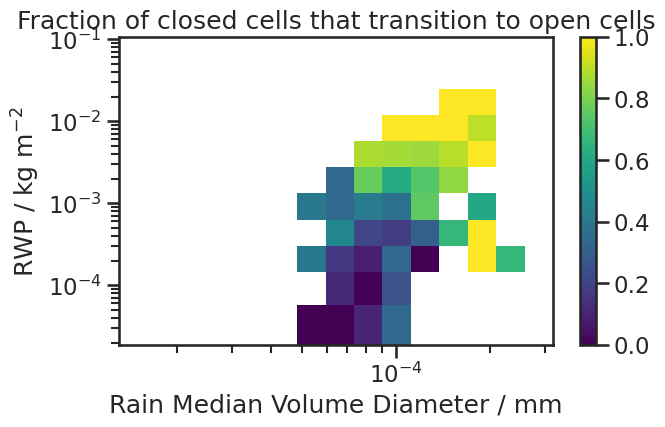

In [ ]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -3.5, 12)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_median_volume_diameter_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_median_volume_diameter_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_median_volume_diameter_bin': rain_median_volume_diameter_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('Rain Median Volume Diameter / mm')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_2544272/1213274747.py:13: RuntimeWarning: invalid value encountered in divide
  rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

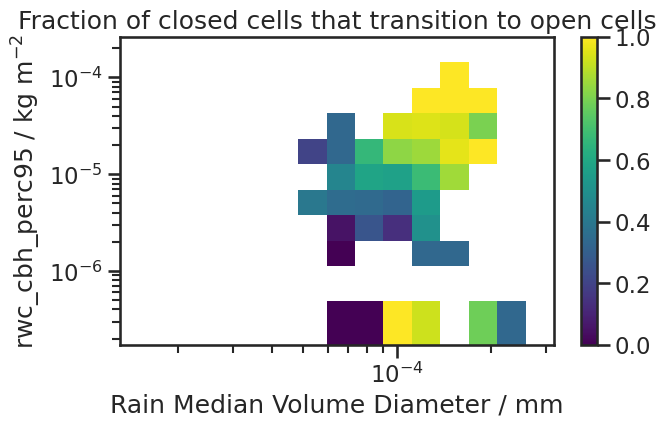

In [ ]:
# plot probability that cloud will transition vs rwc_cbh_perc95
bins_y = np.logspace(-6.5, -3.6, 12)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -3.5, 12)
bins_x[0] = 0

rwc_cbh_perc95_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_median_volume_diameter_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwc_cbh_perc95_hist_trans = np.histogram2d(bt_co_transitioning_c.rwc_cbh_perc95, bt_co_transitioning_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwc_cbh_perc95_hist_non_trans = np.histogram2d(bt_non_trans_c.rwc_cbh_perc95, bt_non_trans_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwc_cbh_perc95_hist_total = rwc_cbh_perc95_hist_trans + rwc_cbh_perc95_hist_non_trans
rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total
rwc_cbh_perc95_transition_prob = np.where(rwc_cbh_perc95_hist_total <= 2, np.nan, rwc_cbh_perc95_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwc_cbh_perc95_transition_prob = xr.DataArray(data=rwc_cbh_perc95_transition_prob, dims=['rwc_cbh_perc95_bin', 'rain_median_volume_diameter_bin'], coords={'rwc_cbh_perc95_bin': rwc_cbh_perc95_bin_centers, 'rain_median_volume_diameter_bin': rain_median_volume_diameter_bin_centers})
plt.figure(figsize=(7, 4))
da_rwc_cbh_perc95_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('rwc_cbh_perc95 / kg m$^{-2}$')
plt.xlabel('Rain Median Volume Diameter / mm')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/2845530616.py:12: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

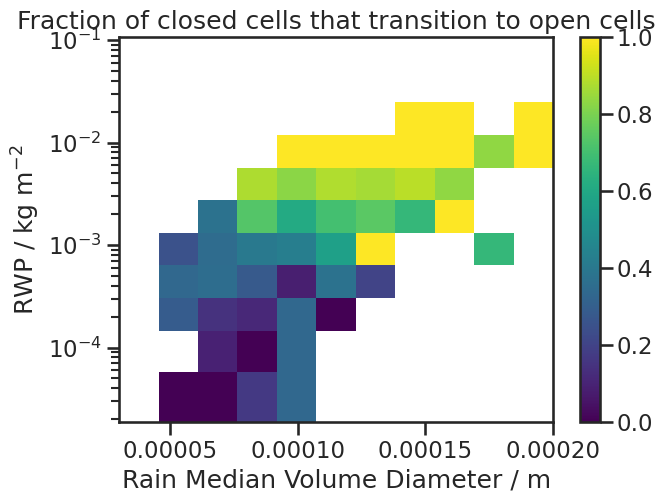

In [ ]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.linspace(3e-5, 2e-4, 12)

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_median_volume_diameter_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_median_volume_diameter_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_median_volume_diameter_bin': rain_median_volume_diameter_bin_centers})
plt.figure(figsize=(7, 5))
da_rwp_transition_prob.plot(yscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('Rain Median Volume Diameter / m')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/2009150771.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

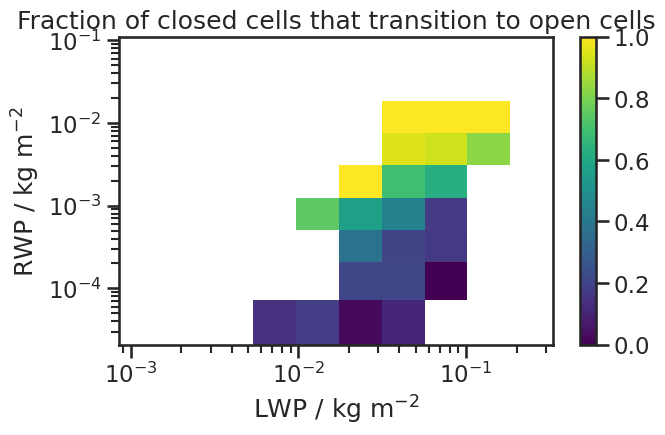

In [ ]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 10)
bins_y[0] = 0
bins_x = np.logspace(-2.8, -0.5, 10)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
lwp_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.lwp, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.lwp, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 3, np.nan, rwp_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'lwp_bin'], coords={'rwp_bin': rwp_bin_centers, 'lwp_bin': lwp_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('LWP / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/2562832824.py:12: RuntimeWarning: invalid value encountered in divide
  rwp_subcloud_transition_prob = rwp_subcloud_hist_trans / rwp_subcloud_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

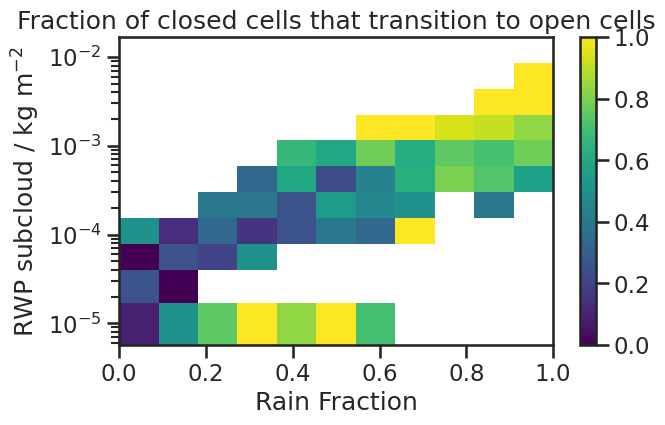

In [ ]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-5, -1.8, 12)
bins_y[0] = 0
bins_x = np.linspace(0, 1, 12)

rwp_subcloud_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_fraction_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_subcloud_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp_subcloud, bt_co_transitioning_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_subcloud_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp_subcloud, bt_non_trans_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_subcloud_hist_total = rwp_subcloud_hist_trans + rwp_subcloud_hist_non_trans
rwp_subcloud_transition_prob = rwp_subcloud_hist_trans / rwp_subcloud_hist_total
rwp_subcloud_transition_prob = np.where(rwp_subcloud_hist_total <= 2, np.nan, rwp_subcloud_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_subcloud_transition_prob = xr.DataArray(data=rwp_subcloud_transition_prob, dims=['rwp_subcloud_bin', 'rain_fraction_bin'], coords={'rwp_subcloud_bin': rwp_subcloud_bin_centers, 'rain_fraction_bin': rain_fraction_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_subcloud_transition_prob.plot(yscale='log', xscale='linear')
plt.ylabel('RWP subcloud / kg m$^{-2}$')
plt.xlabel('Rain Fraction')
plt.title('Fraction of closed cells that transition to open cells')

## compare CO clouds with neighboring non-trans clouds

In [ ]:
tmp = bt_co_forward_from_c.sel(timestep = slice(0,30)).goes_cats.fillna(-1)
enough_datapoints_along_track = (tmp.isin([0,1,2,3,4,5]).sum(dim='timestep')) >= 6
always_closed_cell = tmp.isin([-1,1]).all(dim='timestep')

# new flag: 1 = transition to open cell, 0 = stay closed cell, -1 = something else (not enough data or transition to other category)
bt_co_forward_from_c['flag_closed_cell_transition'] = xr.where(bt_co_forward_from_c.transition_flag, 1, xr.where(~bt_co_forward_from_c.transition_flag & enough_datapoints_along_track & always_closed_cell, 0, -1))

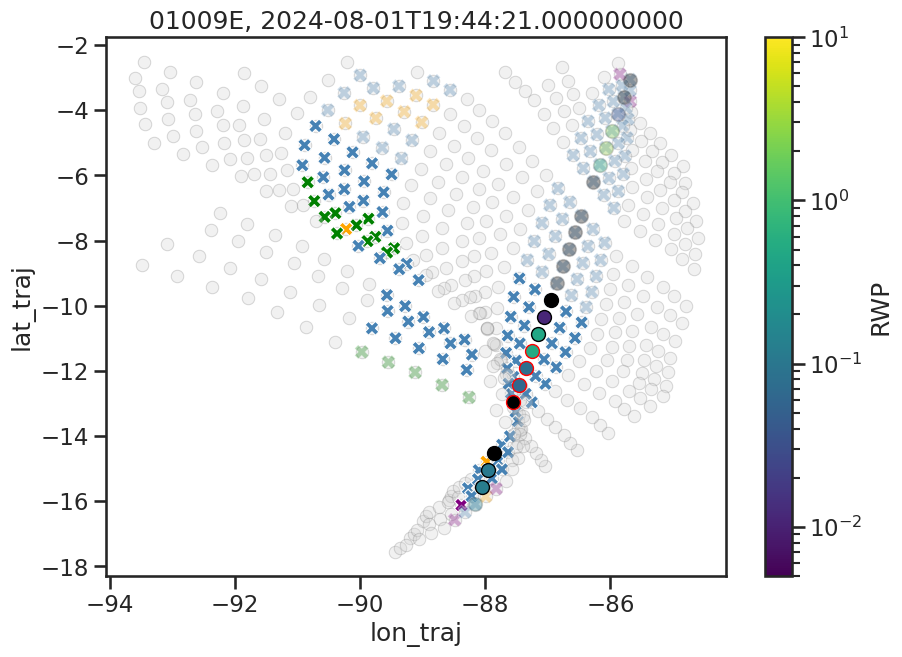

In [ ]:
for orbit, group in bt_co_forward_from_c.groupby('orbit'):
    non_trans_closed_cells = (group.flag_closed_cell_transition == 0).sum()
    co_trans_closed_cells = (group.flag_closed_cell_transition == 1).sum()
    if non_trans_closed_cells > 0 and co_trans_closed_cells > 0:
        
        # Create colormap normalization once outside the loop
        norm = LogNorm(vmin=5e-3, vmax=1e1)
        cmap = plt.cm.viridis
        plt.figure(figsize=(10, 7))
        
        for i in range(len(group.time_startpoint)):
            tmp = group.isel(time_startpoint=i)
            if tmp.flag_closed_cell_transition == 0:
                # persistent closed cell
                alpha = 1.0
                marker_edge_color = 'black'
            elif tmp.flag_closed_cell_transition == 1:
                # transition from closed to open cell
                alpha = 1.0
                marker_edge_color = 'red'
            else:
                alpha = 0.3
                marker_edge_color = 'Grey'

            sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
            
            # Get the RWP value and map it to a color
            rwp_value = tmp.sel(timestep=0).rwp.values*1e3  # convert to g/m²
            color = cmap(norm(rwp_value))
            
            plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 
                    color=color, marker='o', markersize=10, markeredgecolor=marker_edge_color, alpha=alpha)
            sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
        
        # Add colorbar to show the RWP scale
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        plt.colorbar(sm, label='RWP', ax=plt.gca())
        
        plt.title(f'{orbit}, {group.time_startpoint.values[0]}')
        plt.show()
        break

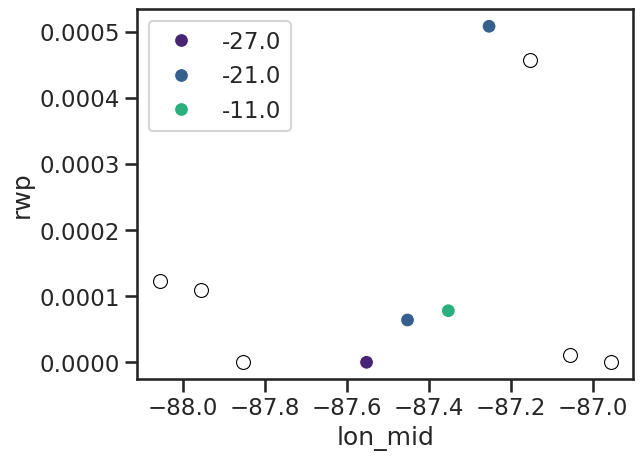

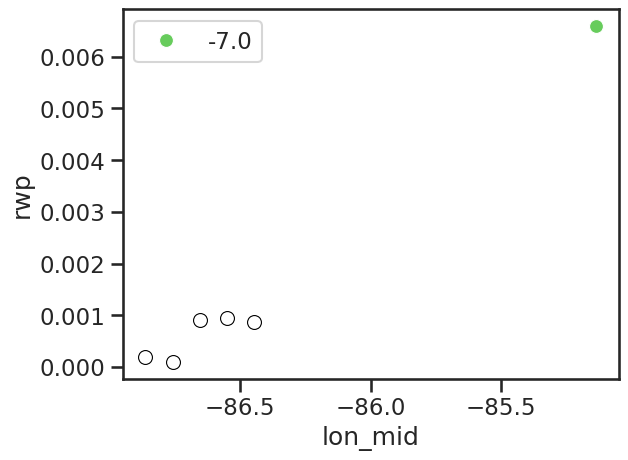

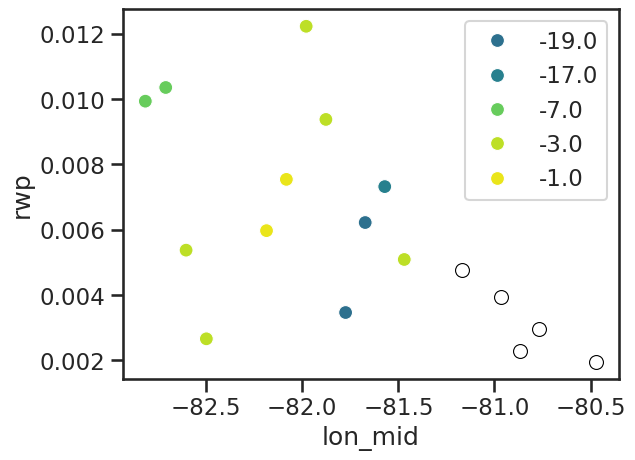

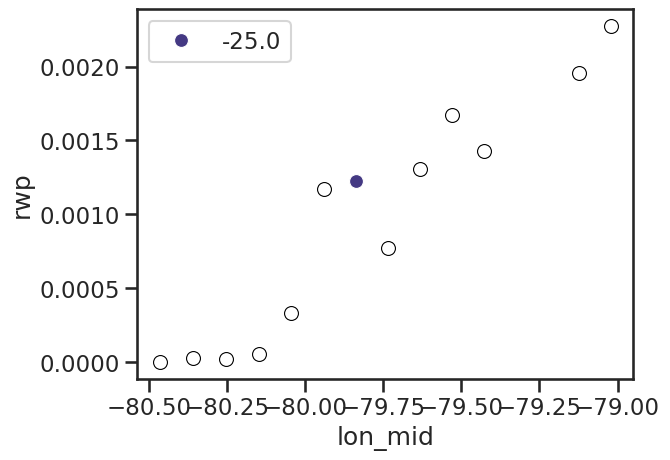

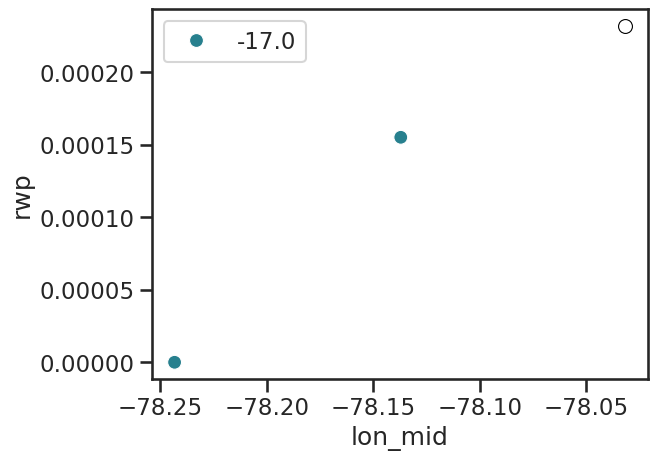

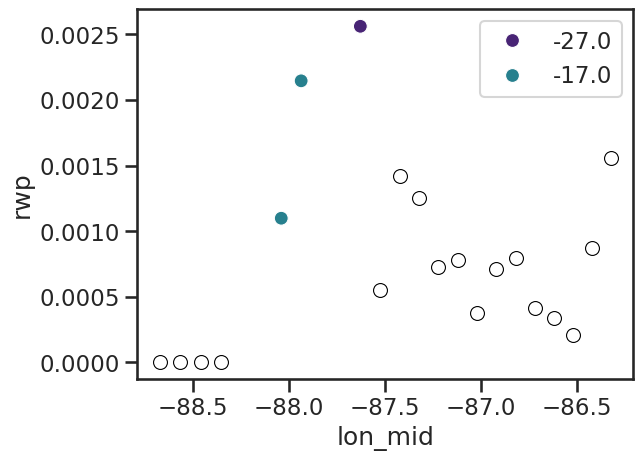

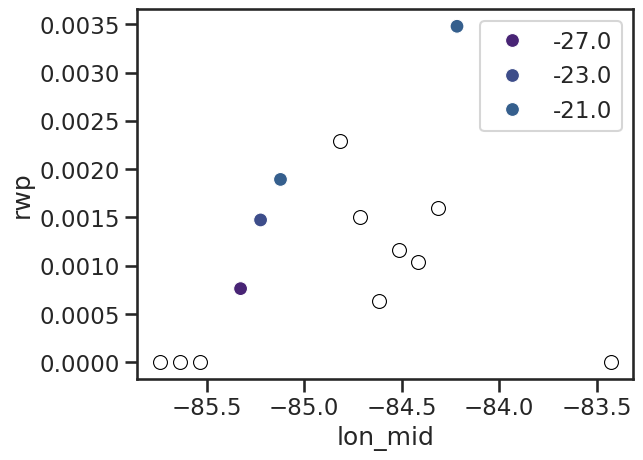

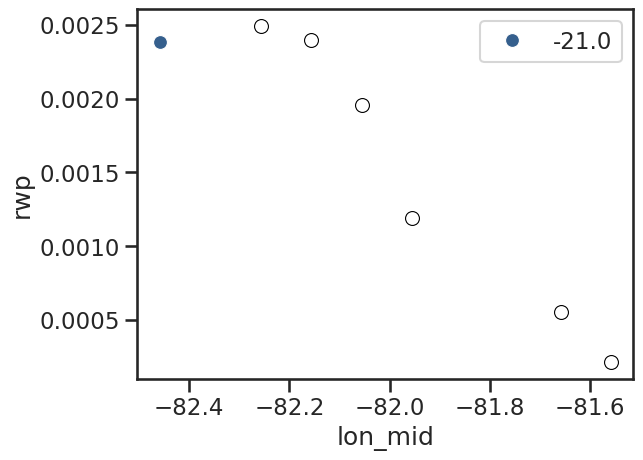

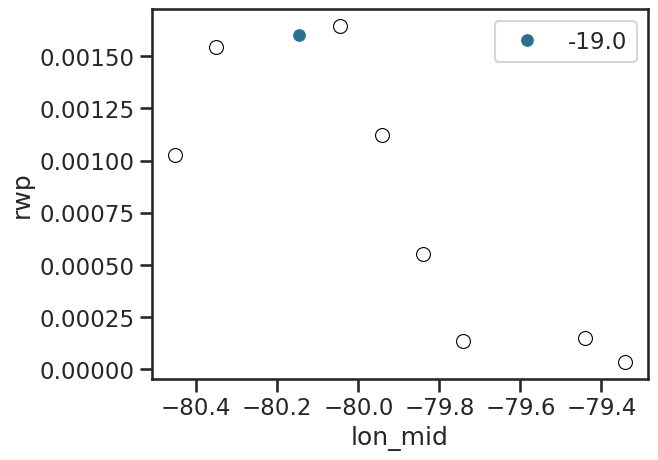

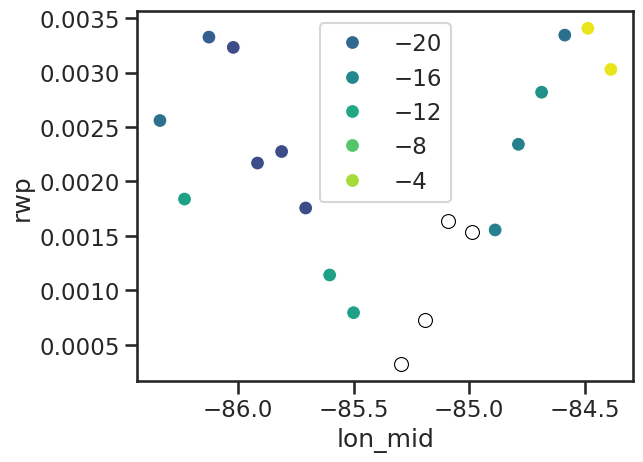

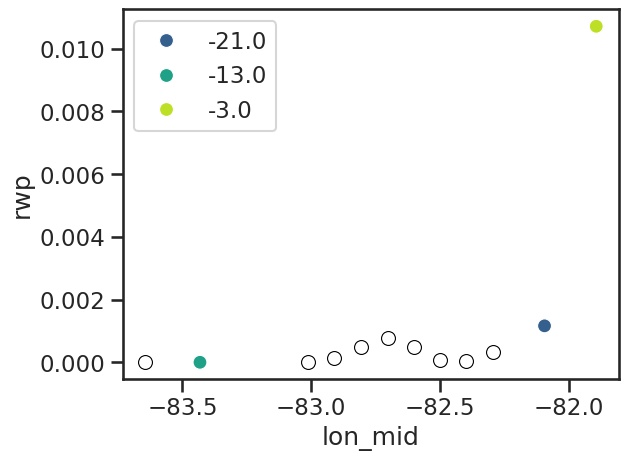

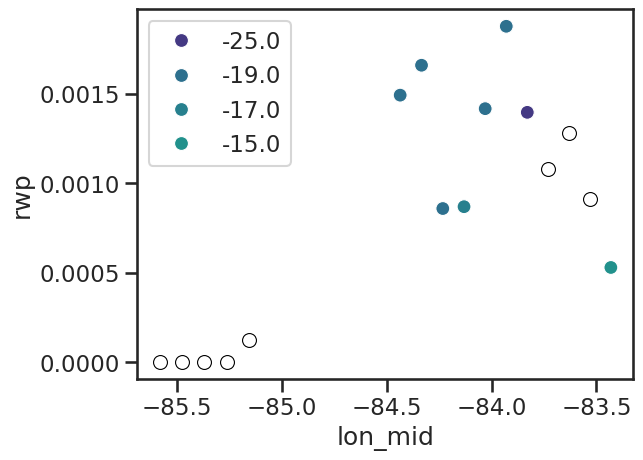

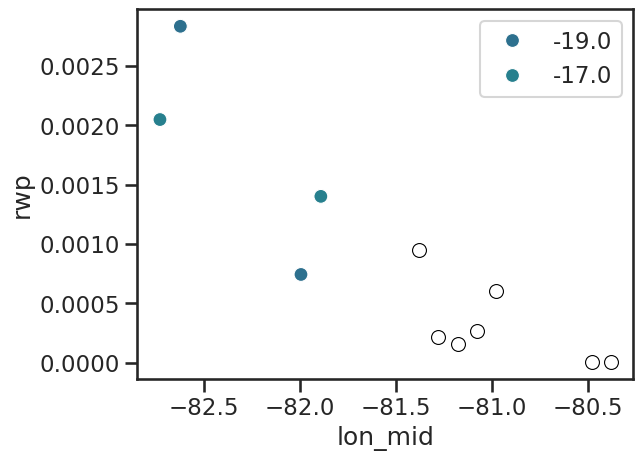

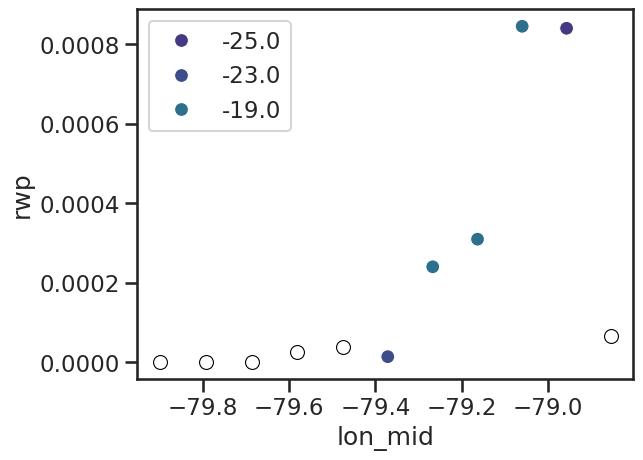

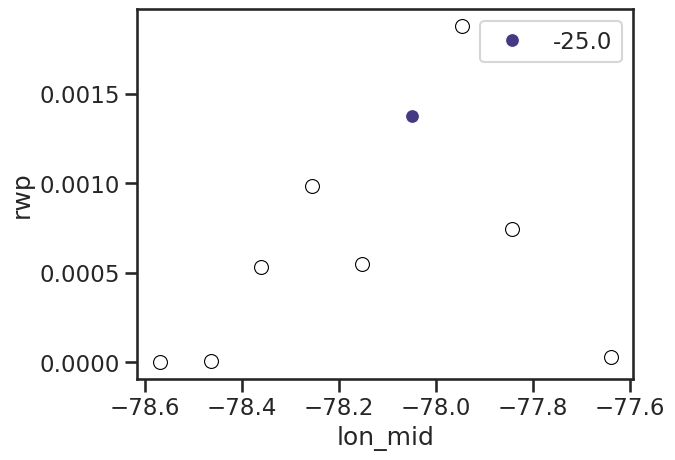

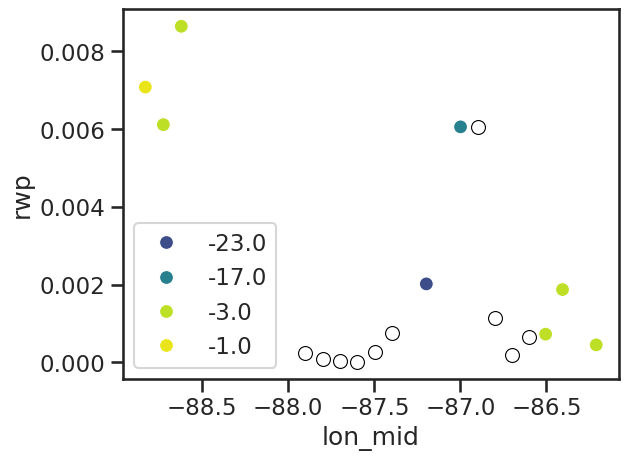

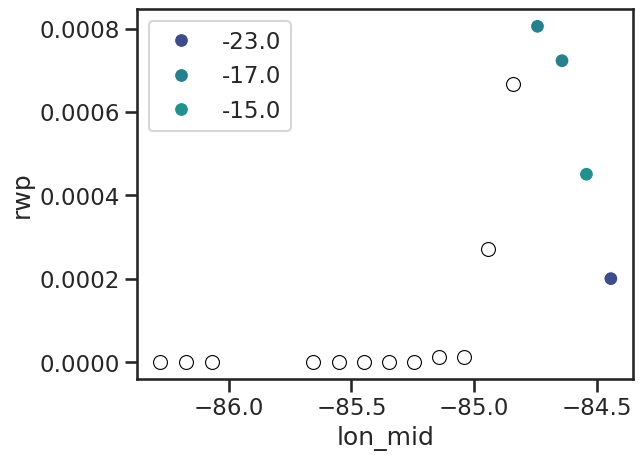

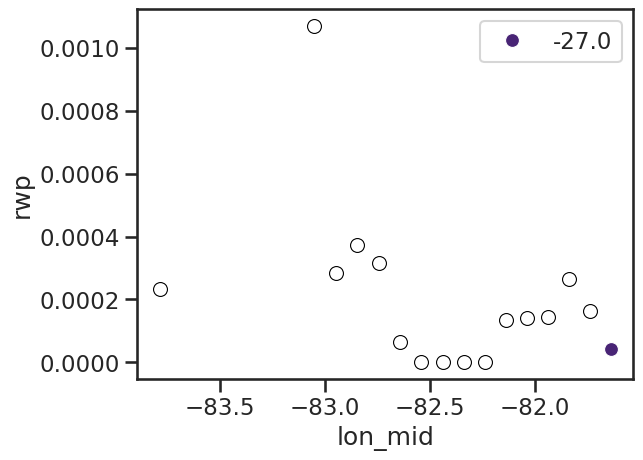

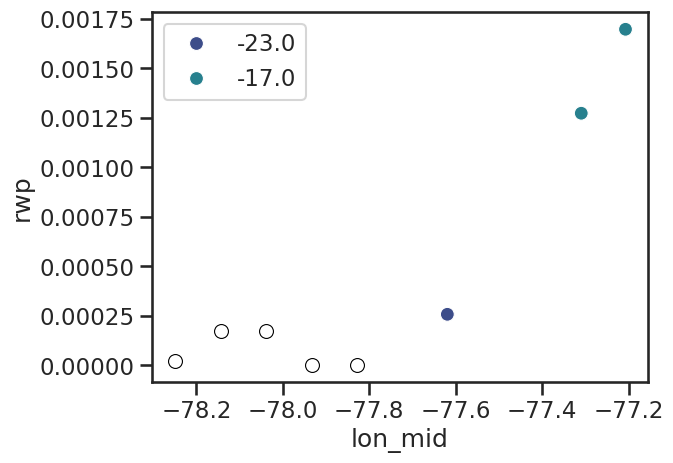

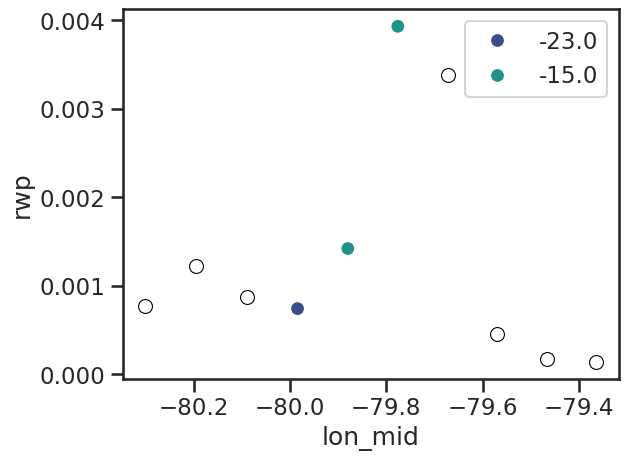

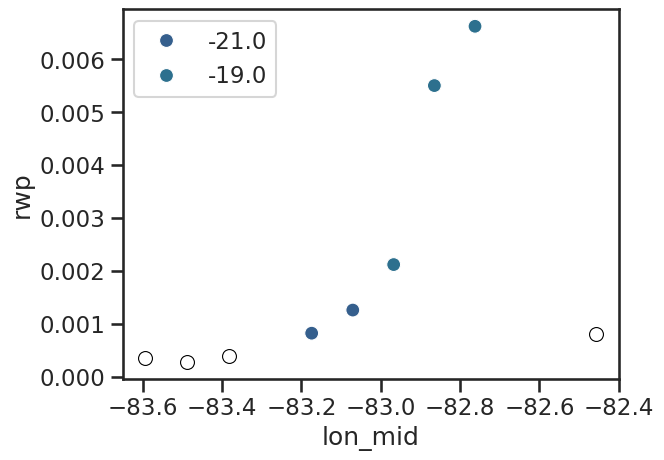

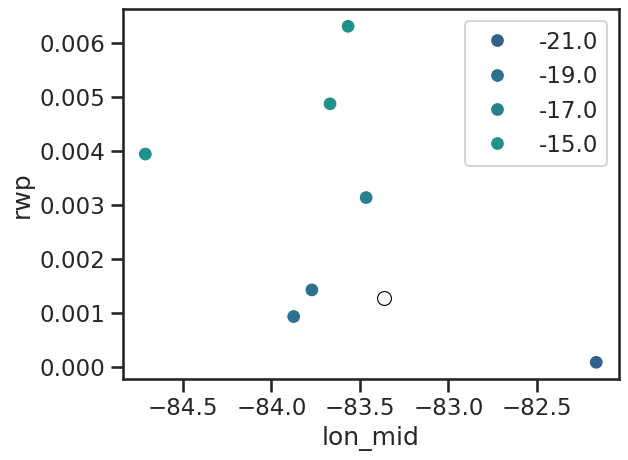

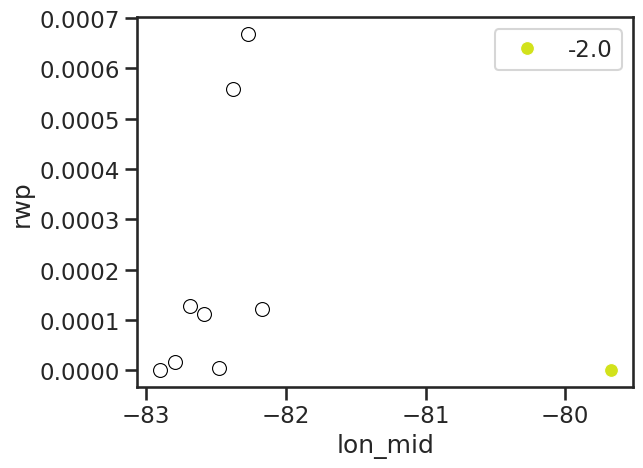

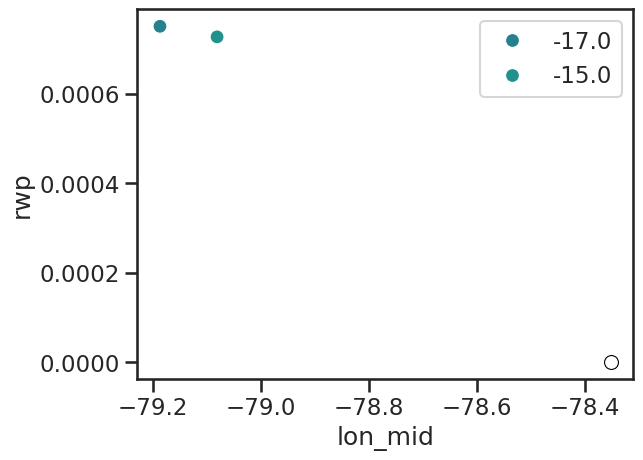

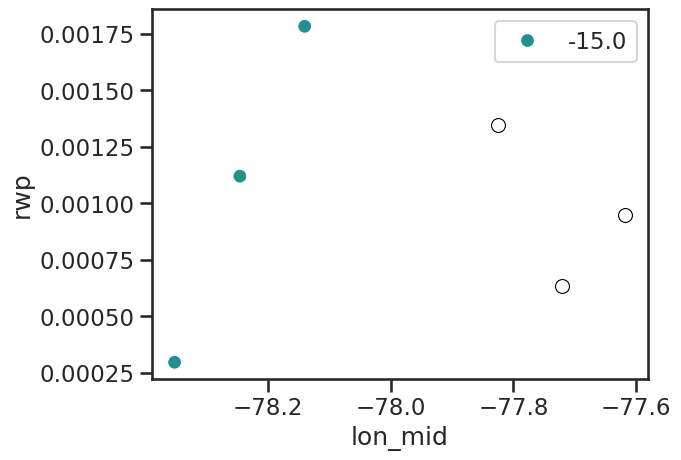

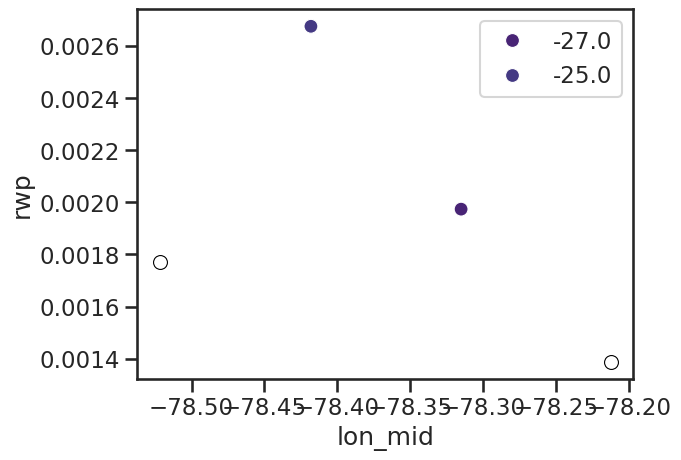

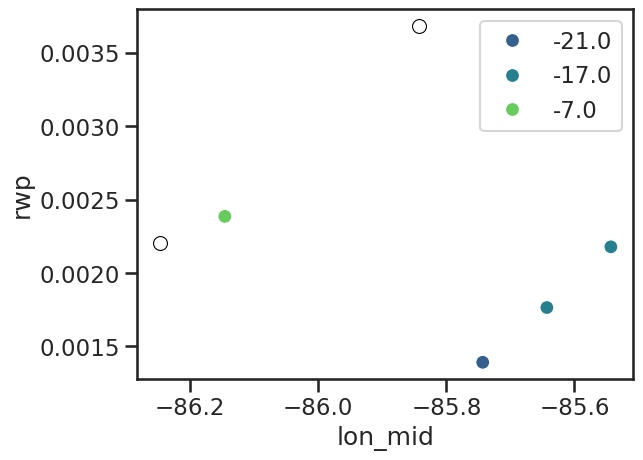

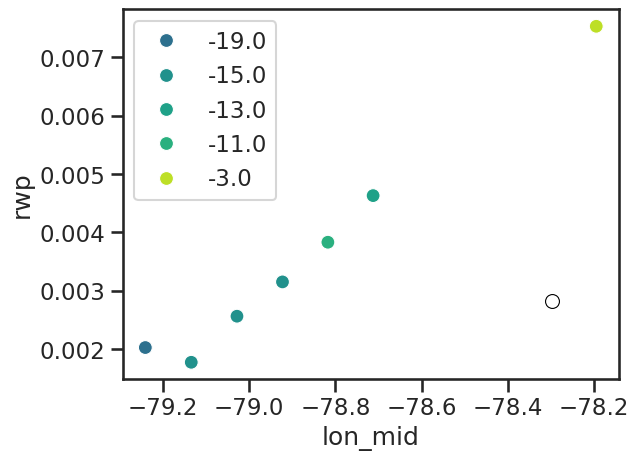

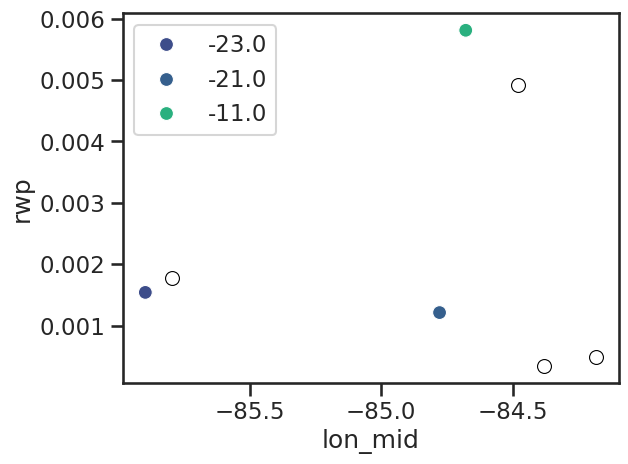

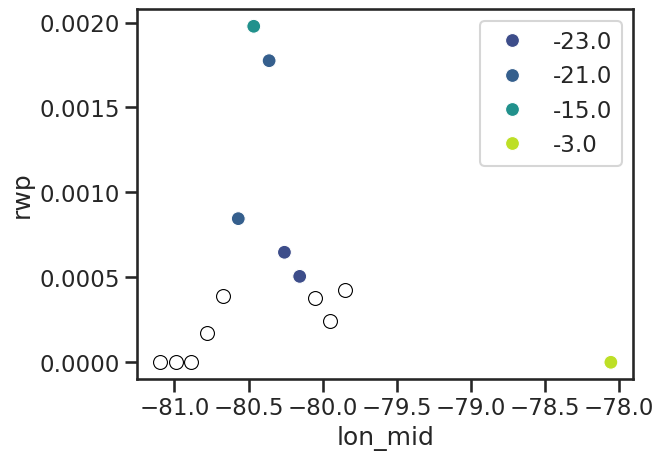

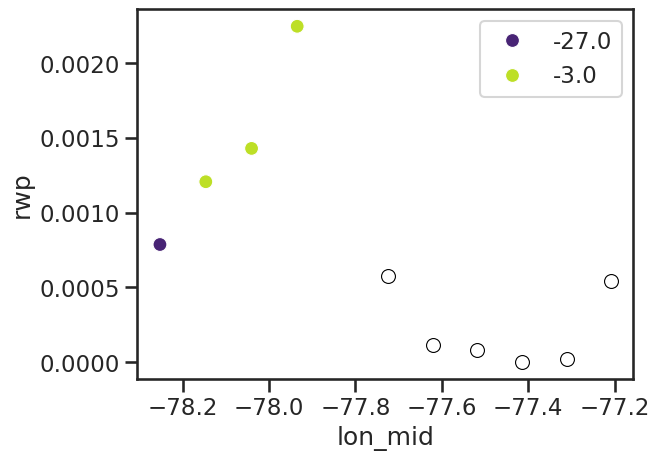

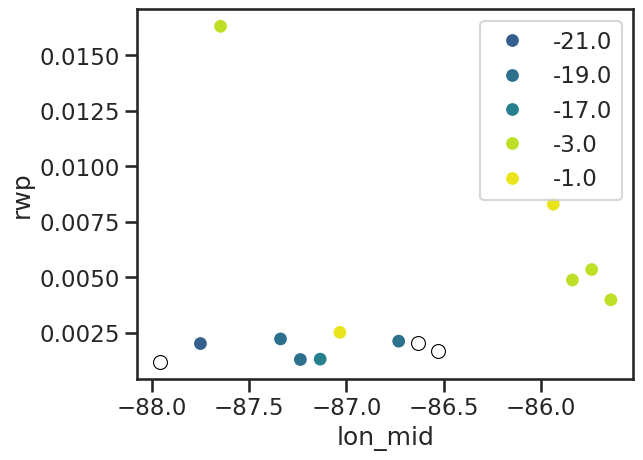

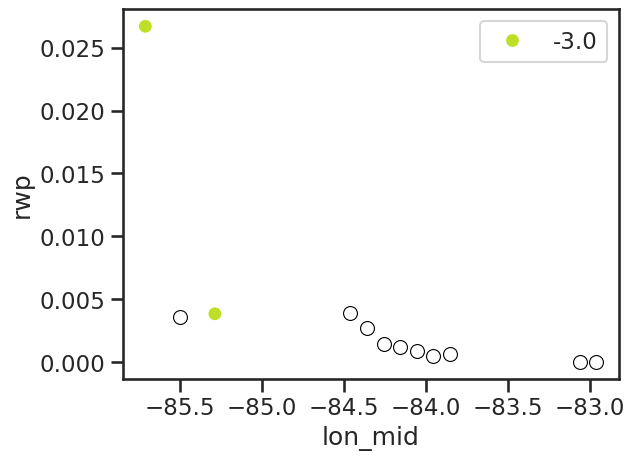

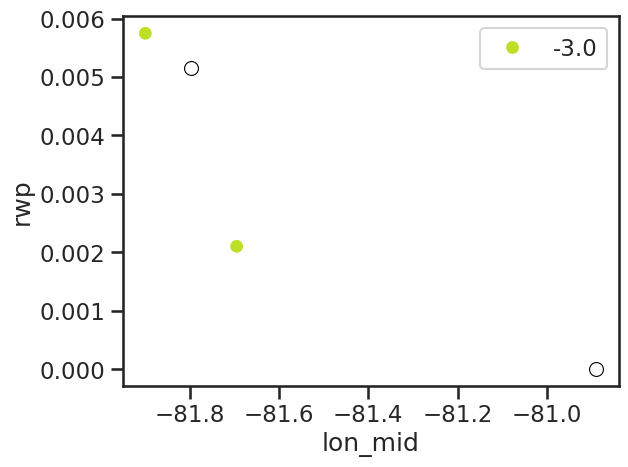

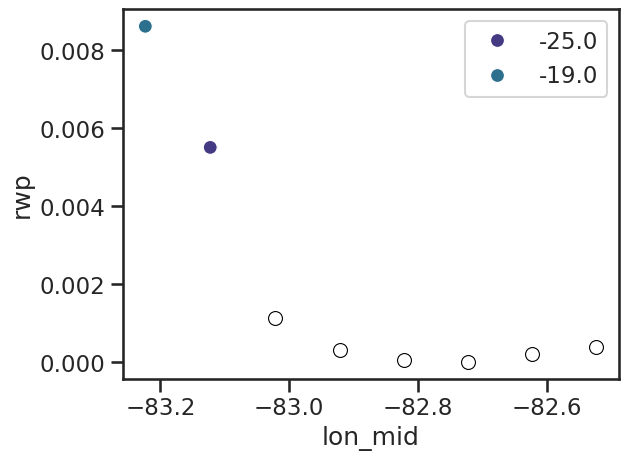

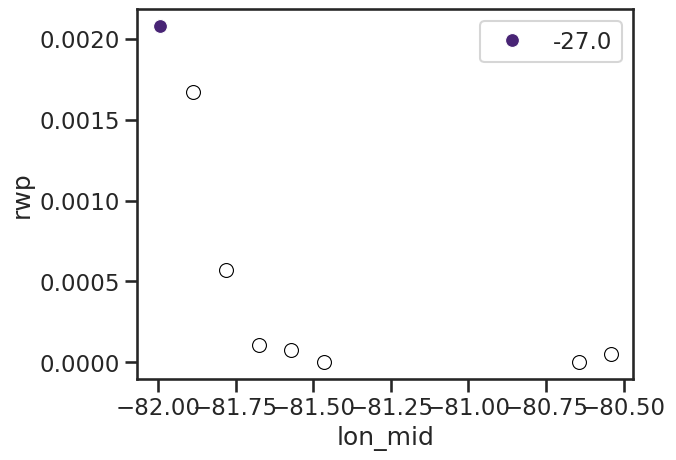

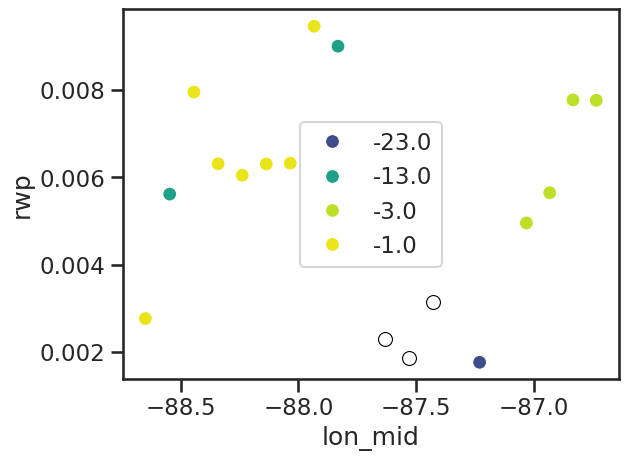

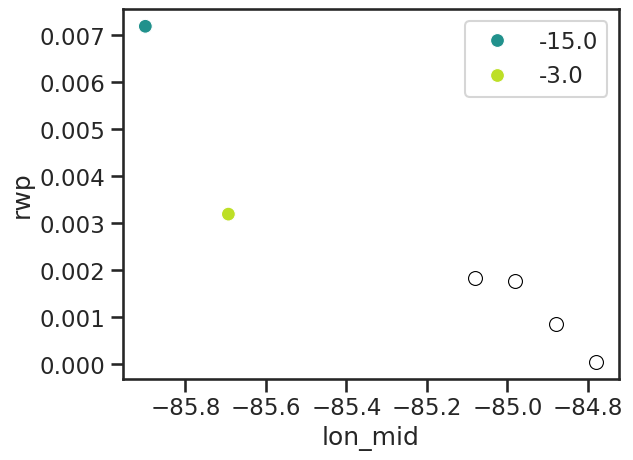

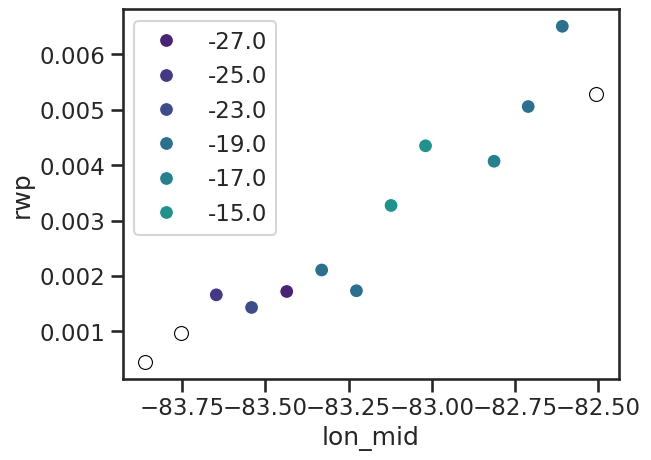

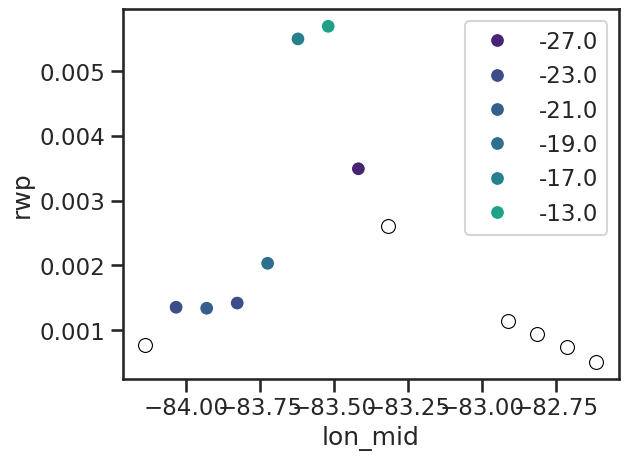

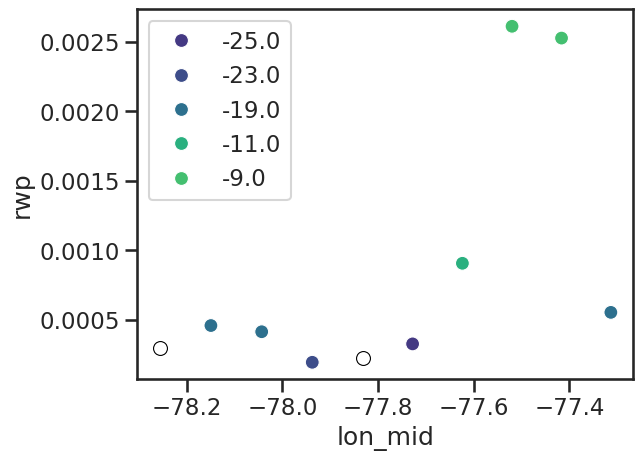

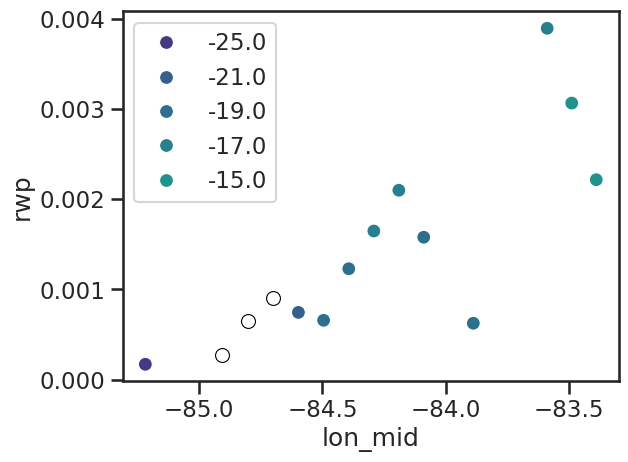

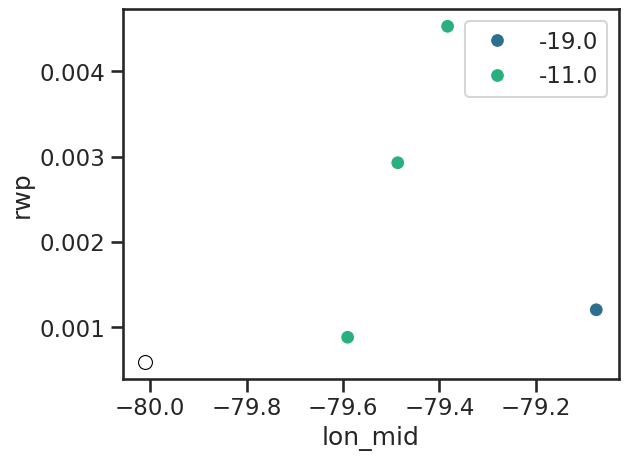

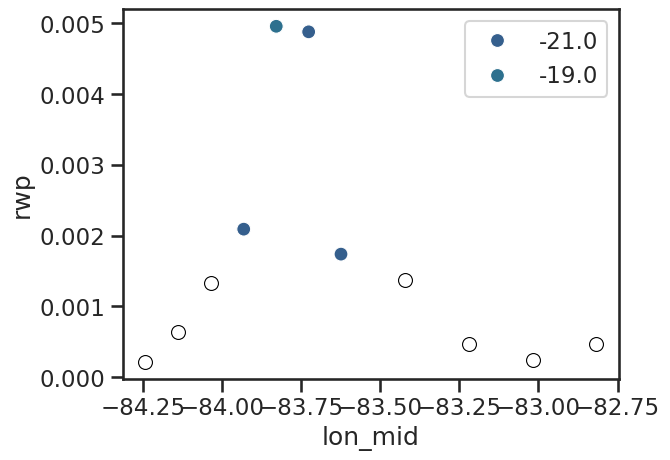

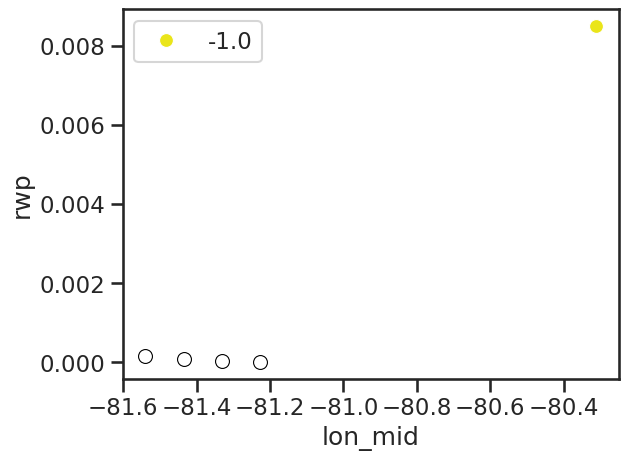

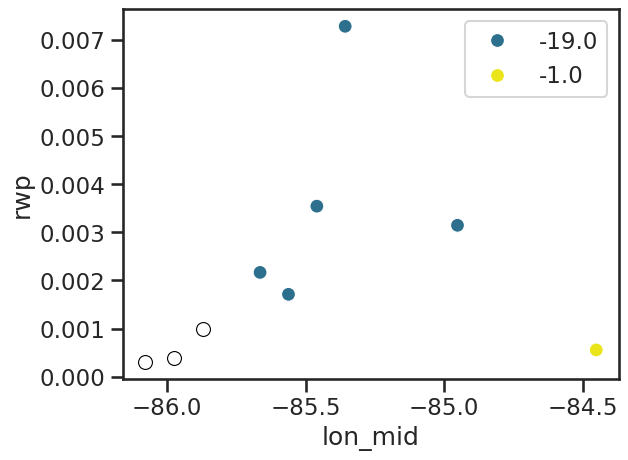

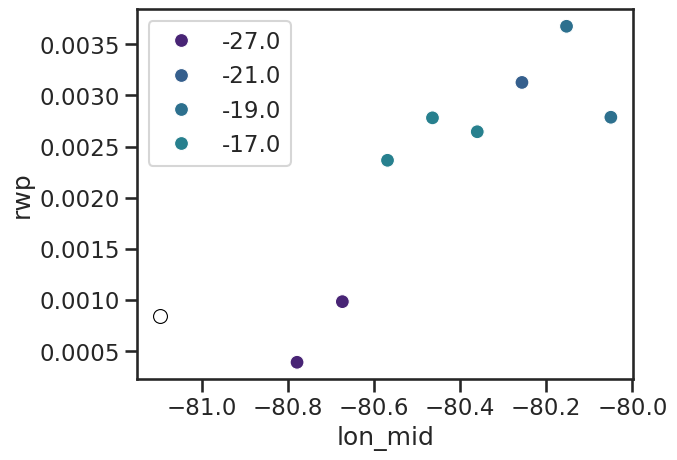

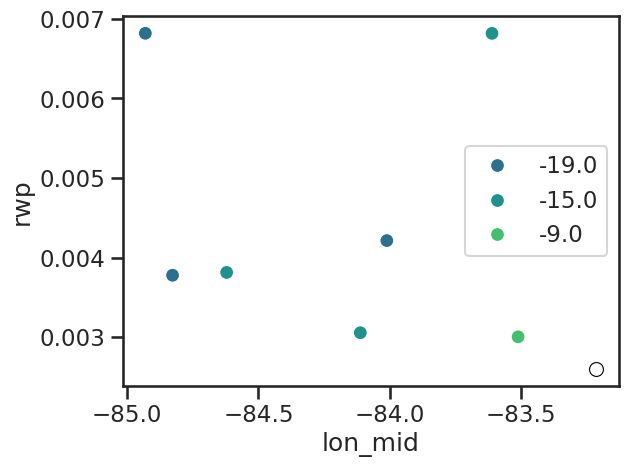

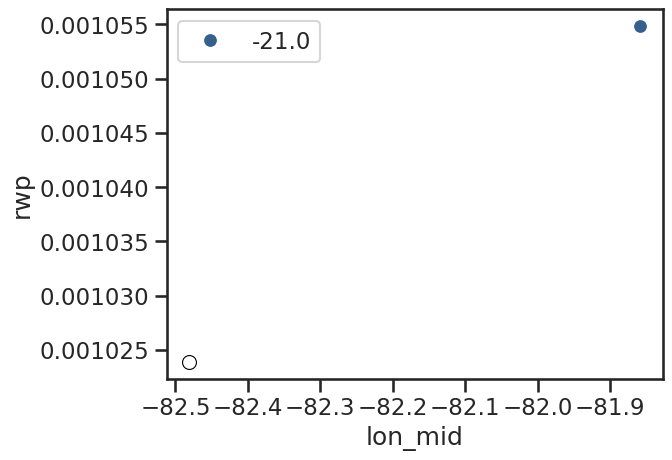

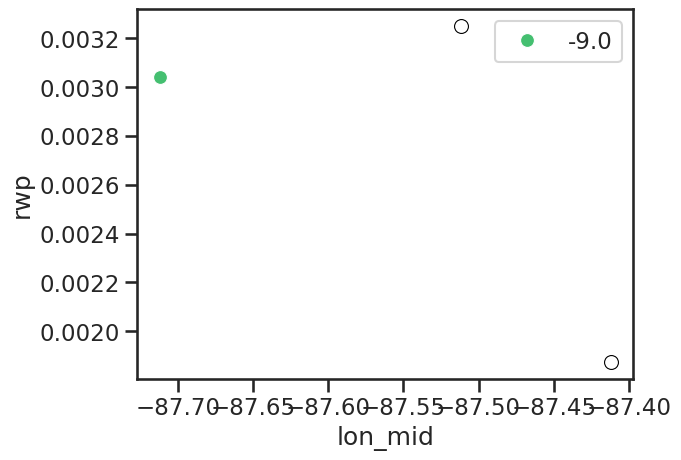

In [ ]:
for orbit, group in bt_co_forward_from_c.groupby('orbit'):
    non_trans_closed_cells = (group.flag_closed_cell_transition == 0).sum()
    co_trans_closed_cells = (group.flag_closed_cell_transition == 1).sum()
    if non_trans_closed_cells > 0 and co_trans_closed_cells > 0:
        sns.scatterplot(data=group.where(group.flag_closed_cell_transition == 1, drop=True), x='lon_mid', y='rwp', hue='transition_time_diff', 
                        palette='viridis', hue_norm=(-30,0), legend=True, marker='o', s=100)
        sns.scatterplot(data=group.where(group.flag_closed_cell_transition == 0, drop=True), x='lon_mid', y='rwp',
                        color='white', legend=True, marker='o', s=100, edgecolor='black')
        plt.show()

## distinguish POC "initiating" and "following" clouds

In [ ]:
bt_C = bt_with_goes.where(bt_with_goes.goes_cat_at_ec_overpass == 1)
bt_co_forward_from_c_all = get_transition_properties(bt_C, transition_from_goes_cats=[1], transition_to_goes_cats=[2], backward=False)

In [ ]:
bt_co_forward_from_c_all['time_diff_to_poc_formation'] = xr.DataArray(np.full(len(bt_co_forward_from_c_all.time_startpoint), np.nan), dims='time_startpoint', 
                                                                      coords={'time_startpoint': bt_co_forward_from_c_all.time_startpoint.values})
bt_co_forward_from_c_all['size_poc'] = xr.DataArray(np.full(len(bt_co_forward_from_c_all.time_startpoint), np.nan), dims='time_startpoint', 
                                                                      coords={'time_startpoint': bt_co_forward_from_c_all.time_startpoint.values})
for orbit, group in bt_co_forward_from_c_all.groupby('orbit'):
    print(orbit)
    #group.transition_flag.plot()
    #group.transition_time_diff.plot()
    
    # find connected clusters of transitioning clouds along the track using scipy label
    from scipy.ndimage import label
    labeled_array, num_features = label(group.transition_flag)

    for feature in range(1, num_features+1):
        mask = (labeled_array == feature)
        feature_group = group.isel({'time_startpoint': mask})  # Adjust dimension name as needed
        first_transition = feature_group.transition_time_diff.max()
        time_diff_to_poc_formation = feature_group.transition_time_diff - first_transition
        size_poc =feature_group.sizes['time_startpoint']
        # Assign values at specific coordinates
        bt_co_forward_from_c_all['time_diff_to_poc_formation'].loc[time_diff_to_poc_formation.time_startpoint] = time_diff_to_poc_formation
        bt_co_forward_from_c_all['size_poc'].loc[time_diff_to_poc_formation.time_startpoint] = size_poc

        #if size_poc >= 2:
        #    feature_group.transition_time_diff.plot(figsize=(4,2), marker='o')
        #    plt.show()

01009E
01024E
01040E
01056E
01071E
01087E
01102E
01133E
01164E
01180E
01195E
01211E
01227E
01242E
01258E
01273E
01289E
01304E
01320E
01335E
01351E
01367E
01382E
01398E
01413E
01460E
01475E
01491E
01522E
01538E
01553E
01569E
01584E
01600E
01616E
01631E
01647E
01678E
01693E
01709E
01724E
01740E
01756E
01771E
01787E
01833E
01849E
01864E
01880E
01896E
01911E
01927E
01942E
02005E
02020E
02036E
02051E
02067E
02082E
02160E
02176E
02191E
02222E
02238E
02253E
02269E
02285E
02300E
02316E
02331E
02378E
02394E
02409E
02425E
02440E
02456E
02471E
02487E
02518E
02534E
02549E
02565E
02596E
02627E
02642E
02658E
02674E
02689E
02705E
02720E
02736E
02751E
02767E
02783E
02798E
02829E
02876E
02891E
02907E
02923E
02938E
02954E
02969E
02985E
03000E
03016E
03031E
03047E
03063E
03078E
03094E
03187E
03203E
03218E
03249E
03265E
03280E
03296E
03312E
03358E
03374E
03389E
03405E
03420E
03436E
03452E
03467E
03483E
03498E
03514E
03529E
03545E
03561E
03576E
03592E
03607E
03623E
03638E
03654E
03669E
03716E
03732E
03747E

In [ ]:
bt_co_forward_from_c_all['time_startpoint'] = bt_co_forward_from_c_all.time_startpoint.dt.round('0.1s')
# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_forward_from_c_all, ds_acmcap, join='left')
# Then merge
bt_co_forward_from_c_all = bt_aligned.merge(acmcap_aligned)

In [ ]:
bt_co_forward_from_c_all

<xarray.Dataset> Size: 93MB
Dimensions:                               (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 103kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 103kB '010...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 4MB ...
    lon_traj                              (time_startpoint, timestep) float64 4MB ...
    plev_traj                             (time_startpoint, timestep) float64 4MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 4MB ...
    goes_cats                             (time_startpoint, timestep) float64 4MB ...
    goes_cert                             (time_startpoint, timestep) float64 4MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 103kB 0.0...
    lwp_cv                                (time_startpoint) float64 103kB 0.5...
    ER_cv                                 (time_startpoint) float64 103kB 0.3...
    Nd_cv                                 (time_startpoint) float64 103kB 0.3...
    rwp_cv                                (time_startpoint) float64 103kB nan...
    rain_median_volume_diameter_cv        (time_startpoint) float64 103kB nan...

In [ ]:
bt_co_forward_from_c = bt_co_forward_from_c_all.where((bt_co_forward_from_c_all.goes_cat_at_ec_overpass == 1) & (bt_co_forward_from_c_all.transition_flag == True), drop=True)

In [ ]:
bt_poc_initiators =bt_co_forward_from_c.where((
                                    (bt_co_forward_from_c.size_poc >= 2)  # only for POC of at least size 2
                                    & (bt_co_forward_from_c.time_diff_to_poc_formation == 0)  # filter for cloud scenes that are the first to transition within their POC
                                    #& (bt_co_forward_from_c.transition_uncertainty < 2),  # filter out nighttime transitions
                                    ),
                                    drop=True)
bt_poc_followers =bt_co_forward_from_c.where((
                                    (bt_co_forward_from_c.size_poc >= 2)  # only for POC of at least size 2
                                    & (bt_co_forward_from_c.time_diff_to_poc_formation < 0)),  # filter for cloud scenes that are the first to transition within their POC
                                    drop=True)

In [ ]:
bt_poc_initiators

<xarray.Dataset> Size: 1MB
Dimensions:                               (time_startpoint: 179, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 1kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 1kB '01009...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 62kB ...
    lon_traj                              (time_startpoint, timestep) float64 62kB ...
    plev_traj                             (time_startpoint, timestep) float64 62kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 62kB ...
    goes_cats                             (time_startpoint, timestep) float64 62kB ...
    goes_cert                             (time_startpoint, timestep) float64 62kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 1kB 0.199...
    lwp_cv                                (time_startpoint) float64 1kB 1.046...
    ER_cv                                 (time_startpoint) float64 1kB 0.565...
    Nd_cv                                 (time_startpoint) float64 1kB 0.675...
    rwp_cv                                (time_startpoint) float64 1kB 7.261...
    rain_median_volume_diameter_cv        (time_startpoint) float64 1kB 0.115...

In [ ]:
bt_poc_followers

<xarray.Dataset> Size: 1MB
Dimensions:                               (time_startpoint: 196, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 2kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 2kB '01009...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 67kB ...
    lon_traj                              (time_startpoint, timestep) float64 67kB ...
    plev_traj                             (time_startpoint, timestep) float64 67kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 67kB ...
    goes_cats                             (time_startpoint, timestep) float64 67kB ...
    goes_cert                             (time_startpoint, timestep) float64 67kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 2kB 0.201...
    lwp_cv                                (time_startpoint) float64 2kB 1.009...
    ER_cv                                 (time_startpoint) float64 2kB 0.481...
    Nd_cv                                 (time_startpoint) float64 2kB 1.087...
    rwp_cv                                (time_startpoint) float64 2kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 2kB 0.442...

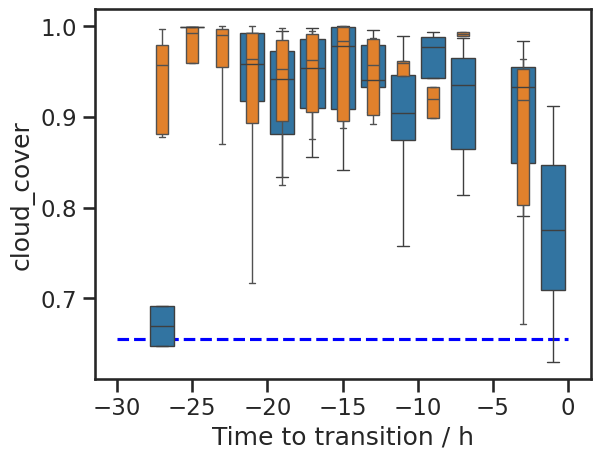

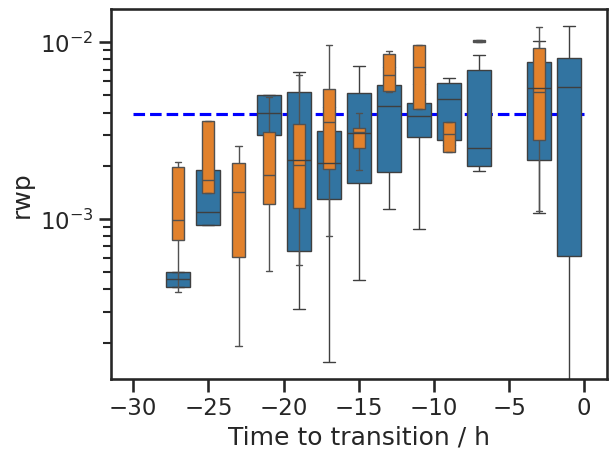

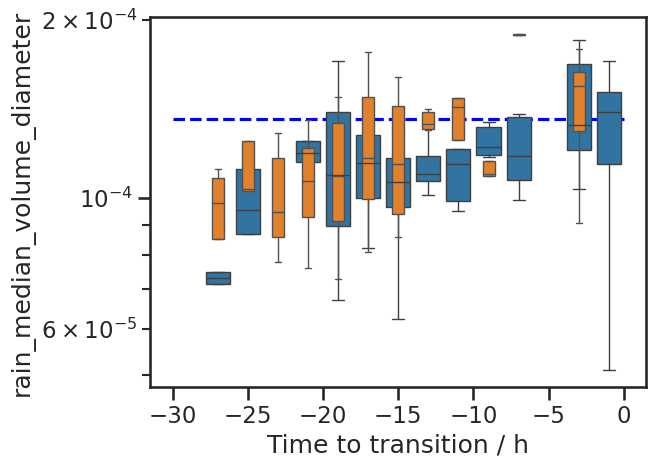

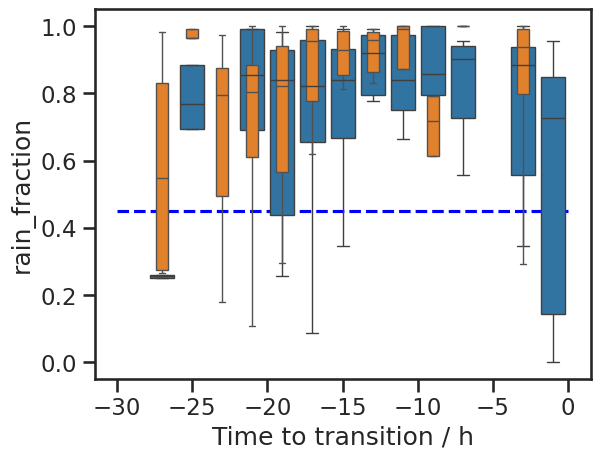

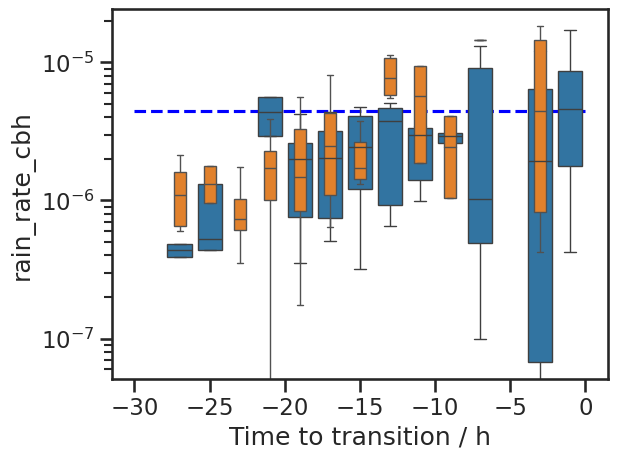

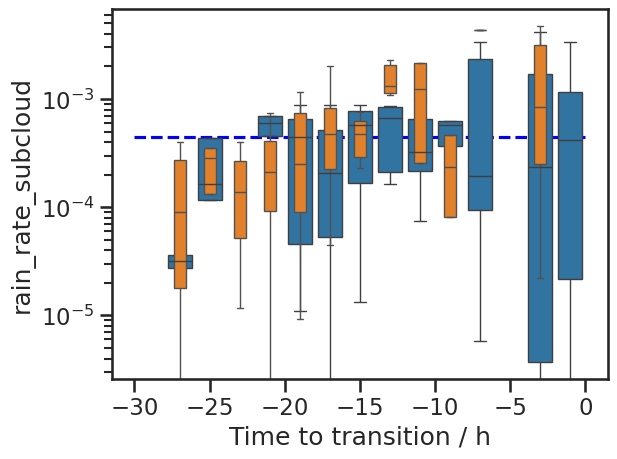

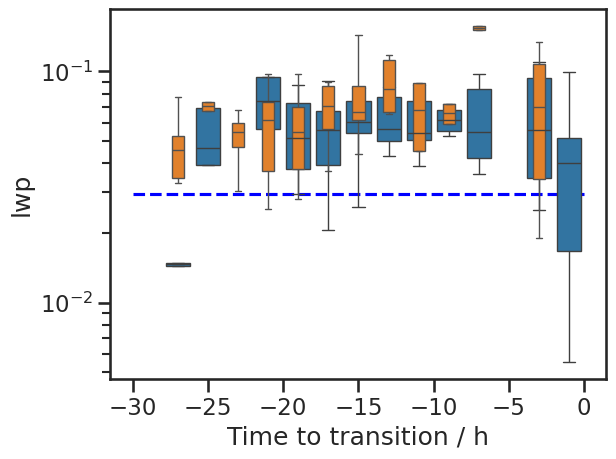

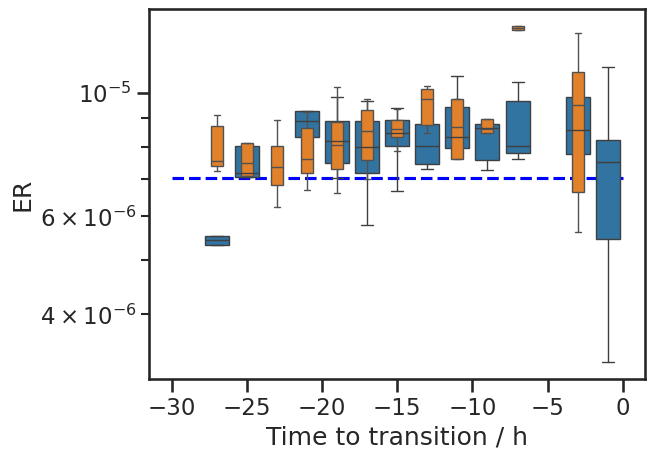

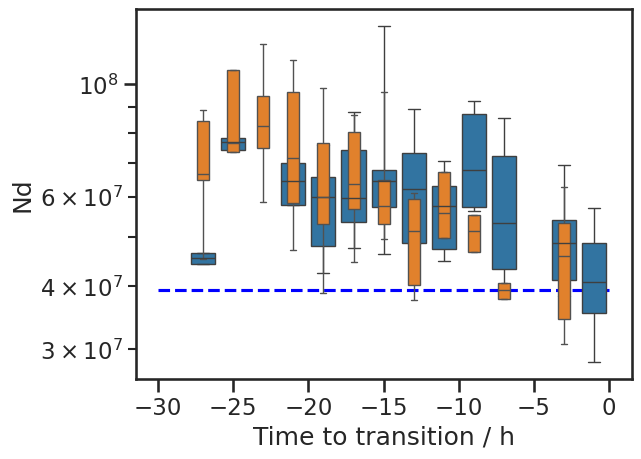

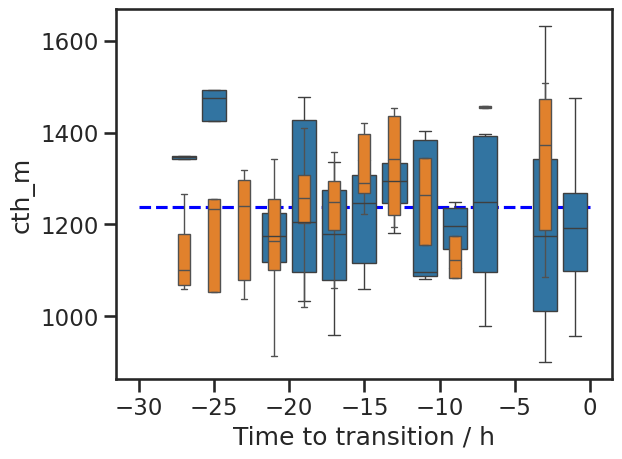

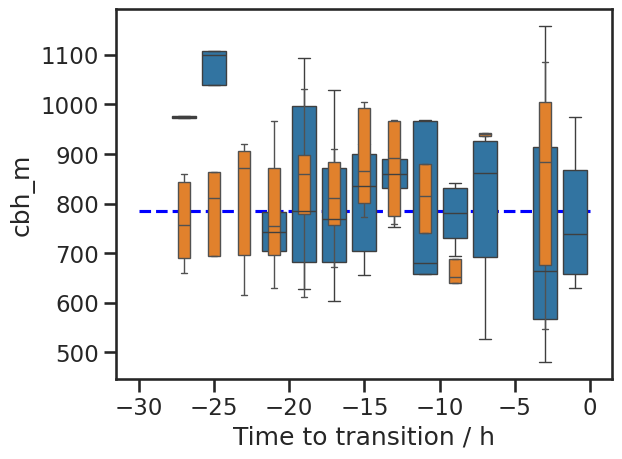

In [ ]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


for var, ylim, yscale in [('cloud_cover', (0, 1), 'linear'),
                          ('rwp', (9e-2, 5e1), 'log'), 
                          ('rain_median_volume_diameter', (1e-5, 1e-3), 'log'),
                          ('rain_fraction', (0, 1), 'linear'),
                          ('rain_rate_cbh', (1e-6, 2e-4), 'log'),
                          ('rain_rate_subcloud', (1e-6, 2e-4), 'log'),
                          ('lwp', (1e-2, 2e-1), 'log'), 
                          ('ER', (5e-6, 2e-5), 'log'),
                          ('Nd', (1e7, 1e9), 'log'),
                          ('cth_m', (0, 3000), 'linear'),
                          ('cbh_m', (0, 3000), 'linear')
                          ]:
    plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=-30, xmax=0, color='blue', linestyle='--')
    sns.boxplot(data = bt_poc_initiators, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=2, showfliers=False)
    sns.boxplot(data = bt_poc_followers, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=1.5, showfliers=False)
    plt.yscale(yscale)
    #plt.ylim(ylim)
    plt.xlabel('Time to transition / h')
    plt.show()

## distinguish POC and larger-scale open cells

In [ ]:
bt_poc =bt_co_forward_from_c.where(
                                    (bt_co_forward_from_c.size_poc <= 5), 
                                    drop=True)
bt_largescale_open =bt_co_forward_from_c.where(
                                    (bt_co_forward_from_c.size_poc > 5),  
                                    drop=True)

In [ ]:
bt_poc

<xarray.Dataset> Size: 2MB
Dimensions:                               (time_startpoint: 334, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 3kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 3kB '01009...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 115kB ...
    lon_traj                              (time_startpoint, timestep) float64 115kB ...
    plev_traj                             (time_startpoint, timestep) float64 115kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 115kB ...
    goes_cats                             (time_startpoint, timestep) float64 115kB ...
    goes_cert                             (time_startpoint, timestep) float64 115kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 3kB 0.201...
    lwp_cv                                (time_startpoint) float64 3kB 1.009...
    ER_cv                                 (time_startpoint) float64 3kB 0.481...
    Nd_cv                                 (time_startpoint) float64 3kB 1.087...
    rwp_cv                                (time_startpoint) float64 3kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 3kB 0.442...

In [ ]:
bt_largescale_open

<xarray.Dataset> Size: 992kB
Dimensions:                               (time_startpoint: 138, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 1kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 1kB '01071...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 47kB ...
    lon_traj                              (time_startpoint, timestep) float64 47kB ...
    plev_traj                             (time_startpoint, timestep) float64 47kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 47kB ...
    goes_cats                             (time_startpoint, timestep) float64 47kB ...
    goes_cert                             (time_startpoint, timestep) float64 47kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 1kB 0.112...
    lwp_cv                                (time_startpoint) float64 1kB 0.696...
    ER_cv                                 (time_startpoint) float64 1kB 0.276...
    Nd_cv                                 (time_startpoint) float64 1kB 0.588...
    rwp_cv                                (time_startpoint) float64 1kB 0.816...
    rain_median_volume_diameter_cv        (time_startpoint) float64 1kB 0.270...

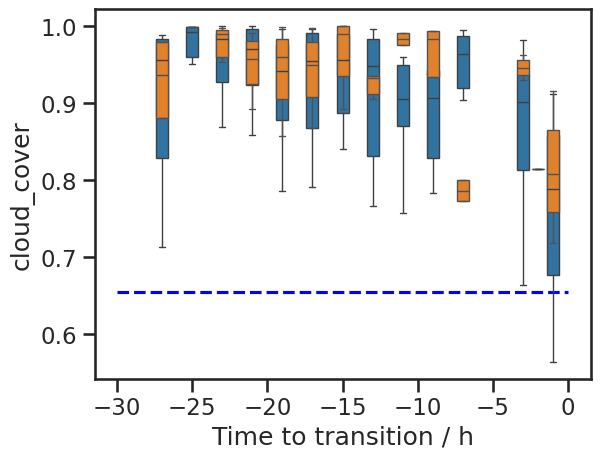

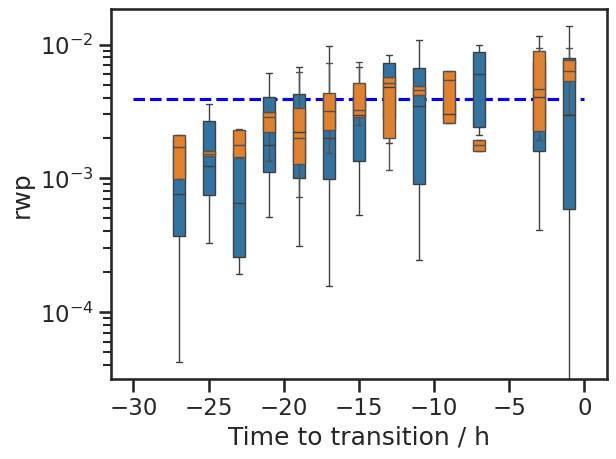

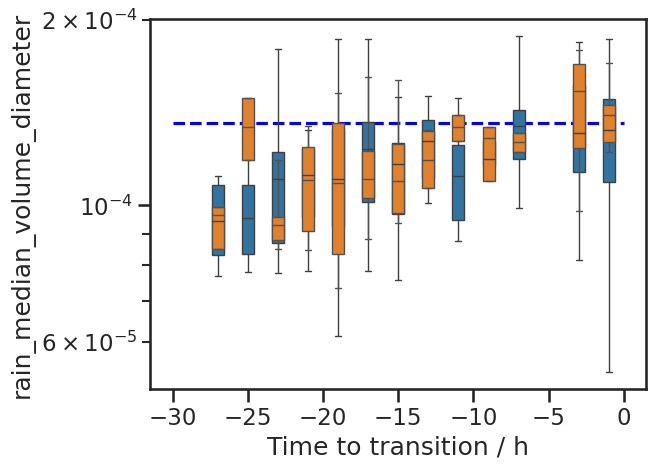

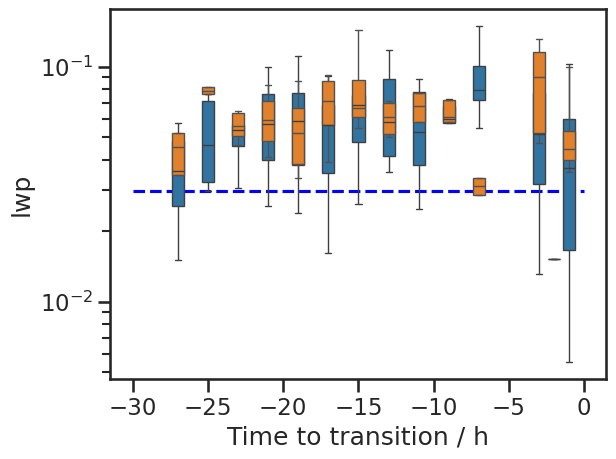

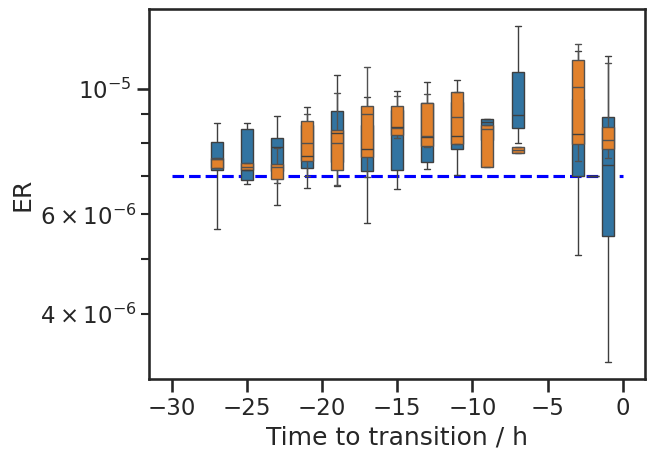

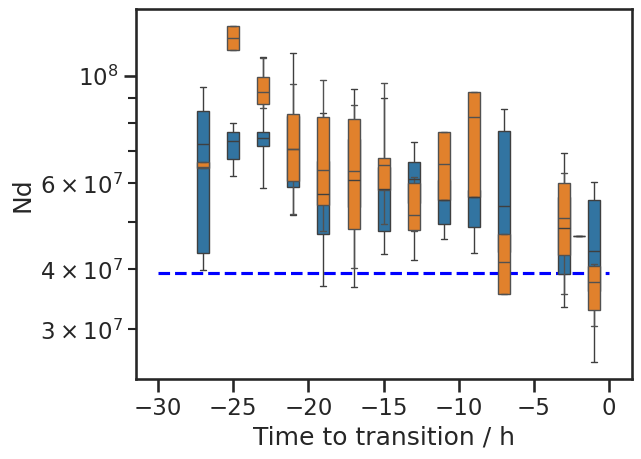

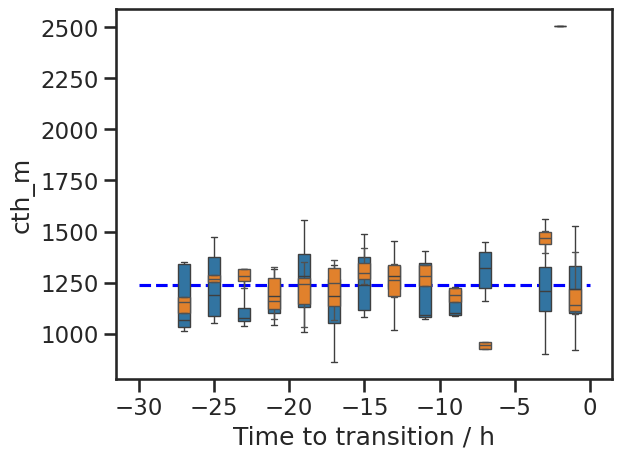

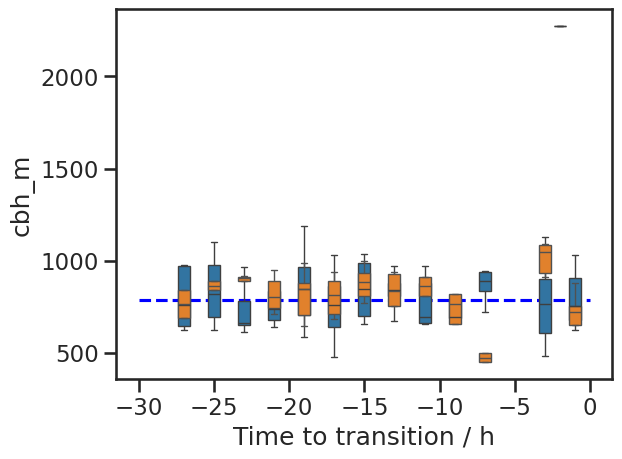

In [ ]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


for var, ylim, yscale in [('cloud_cover', (0, 1), 'linear'),
                          ('rwp', (9e-2, 5e1), 'log'), 
                          ('rain_median_volume_diameter', (1e-5, 1e-3), 'log'),
                          ('lwp', (1e-2, 2e-1), 'log'), 
                          ('ER', (5e-6, 2e-5), 'log'),
                          ('Nd', (1e7, 1e9), 'log'),
                          ('cth_m', (0, 3000), 'linear'),
                          ('cbh_m', (0, 3000), 'linear')
                          ]:
    plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=-30, xmax=0, color='blue', linestyle='--')
    sns.boxplot(data = bt_poc, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=2, showfliers=False)
    sns.boxplot(data = bt_largescale_open, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=1.5, showfliers=False)
    plt.yscale(yscale)
    #plt.ylim(ylim)
    plt.xlabel('Time to transition / h')
    plt.show()